In [87]:
!pip install pydicom


[notice] A new release of pip is available: 23.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [21]:
# ============================================================
# CONFIGURACIÓN GENERAL Y RUTA DE ACCESO UNIFICADA
# ============================================================
import os
import pydicom
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image


# PARTE 1 — Imagen plana (base teórica)

En esta parte trabajamos con una **imagen plana bidimensional** (capturada por una cámara, 8 bits por canal) para entender los conceptos base que luego aplicaremos a las imágenes médicas (resonancia y tomografía).

Conceptos que cubrimos aquí:
1. Abrir la imagen con `PIL` y ver su **matriz** y sus **canales** (R, G, B, y alfa si existe).
2. Entender los **valores de intensidad** (0–255, 8 bits → 256 niveles por canal).
3. Función **`histograma()` genérica** (sirve para imagen plana, resonancia y tomografía).
4. Histograma **por canal** (R, G, B).
5. Detección del **tipo de ruido** con la prueba de **Kolmogorov–Smirnov** (en imagen plana el ruido es **gaussiano**).
6. **Ecualización del histograma**.


## 1.1 Abrir la imagen plana y ver su matriz

Usamos `PIL` (Pillow) para abrir la imagen, y `numpy` para verla como matriz.
El objetivo es comprobar: dimensiones (alto × ancho), número de canales y tipo de dato.


Modo (PIL):         RGB
Tamaño (ancho,alto): (960, 1280)
Shape (matriz):     (1280, 960, 3)  -> (alto, ancho, canales)
dtype:              uint8
Valor mínimo:       0
Valor máximo:       255
Número de canales:  3


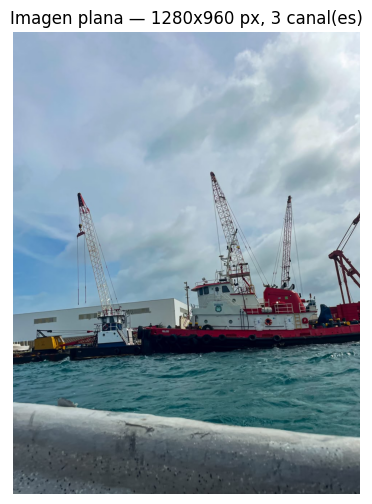


Bits por canal (8 bits): 0 a 255 -> 256 niveles por canal
Total colores RGB posibles: 256^3 = 16,777,216 (aprox. 16.7 millones)


In [10]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

RUTA_PLANA = "imagenes/imagen plana/mar.jpeg"

# Abrir la imagen con PIL
imagen_pil = Image.open(RUTA_PLANA)

# Convertir a matriz numpy
imagen_plana = np.array(imagen_pil)

print("Modo (PIL):        ", imagen_pil.mode)
print("Tamaño (ancho,alto):", imagen_pil.size)
print("Shape (matriz):    ", imagen_plana.shape, " -> (alto, ancho, canales)")
print("dtype:             ", imagen_plana.dtype)
print("Valor mínimo:      ", imagen_plana.min())
print("Valor máximo:      ", imagen_plana.max())

# ¿Cuántos canales tiene?
canales = imagen_plana.shape[2] if imagen_plana.ndim == 3 else 1
print("Número de canales: ", canales)

# Mostrar la imagen
plt.figure(figsize=(10, 6))
plt.imshow(imagen_plana)
plt.title(f"Imagen plana — {imagen_plana.shape[0]}x{imagen_plana.shape[1]} px, {canales} canal(es)")
plt.axis("off")
plt.show()

# Recordatorio de profundidad de bits:
# dtype uint8 -> enteros de 0 a 255 -> 2^8 = 256 niveles por canal -> 8 bits
print("\nBits por canal (8 bits): 0 a 255 ->", 2**8, "niveles por canal")
if canales == 3:
    print(f"Total colores RGB posibles: 256^3 = {256**3:,} (aprox. 16.7 millones)")


## Valores numéricos de la imagen plana

Se convierte la imagen plana en una matriz numérica con NumPy y se imprime el valor del primer píxel (fila 0, columna 0). Como la imagen es a color, el resultado son 3 valores **[R, G, B]**, cada uno entre 0 y 255.


In [11]:
import numpy as librerianumpy
from PIL import Image

# Abrir la imagen plana
mi_imagen = Image.open("imagenes/imagen plana/foto.jpg")

# Convertir la imagen a matriz numérica
datos_numericos_imagen = librerianumpy.array(mi_imagen)

# Valor del primer píxel (fila 0, columna 0)
print(datos_numericos_imagen[0][0])


[121 141 168]


## 1.2 Canales de color (R, G, B) e histogramas

Una imagen a color se compone de **3 matrices superpuestas**: una por canal **R**ojo, **G**verde y **A**zul (RGB).
Algunas imágenes traen un **cuarto canal (alfa)** que mide transparencia. En esta imagen veremos cuántos canales hay realmente.


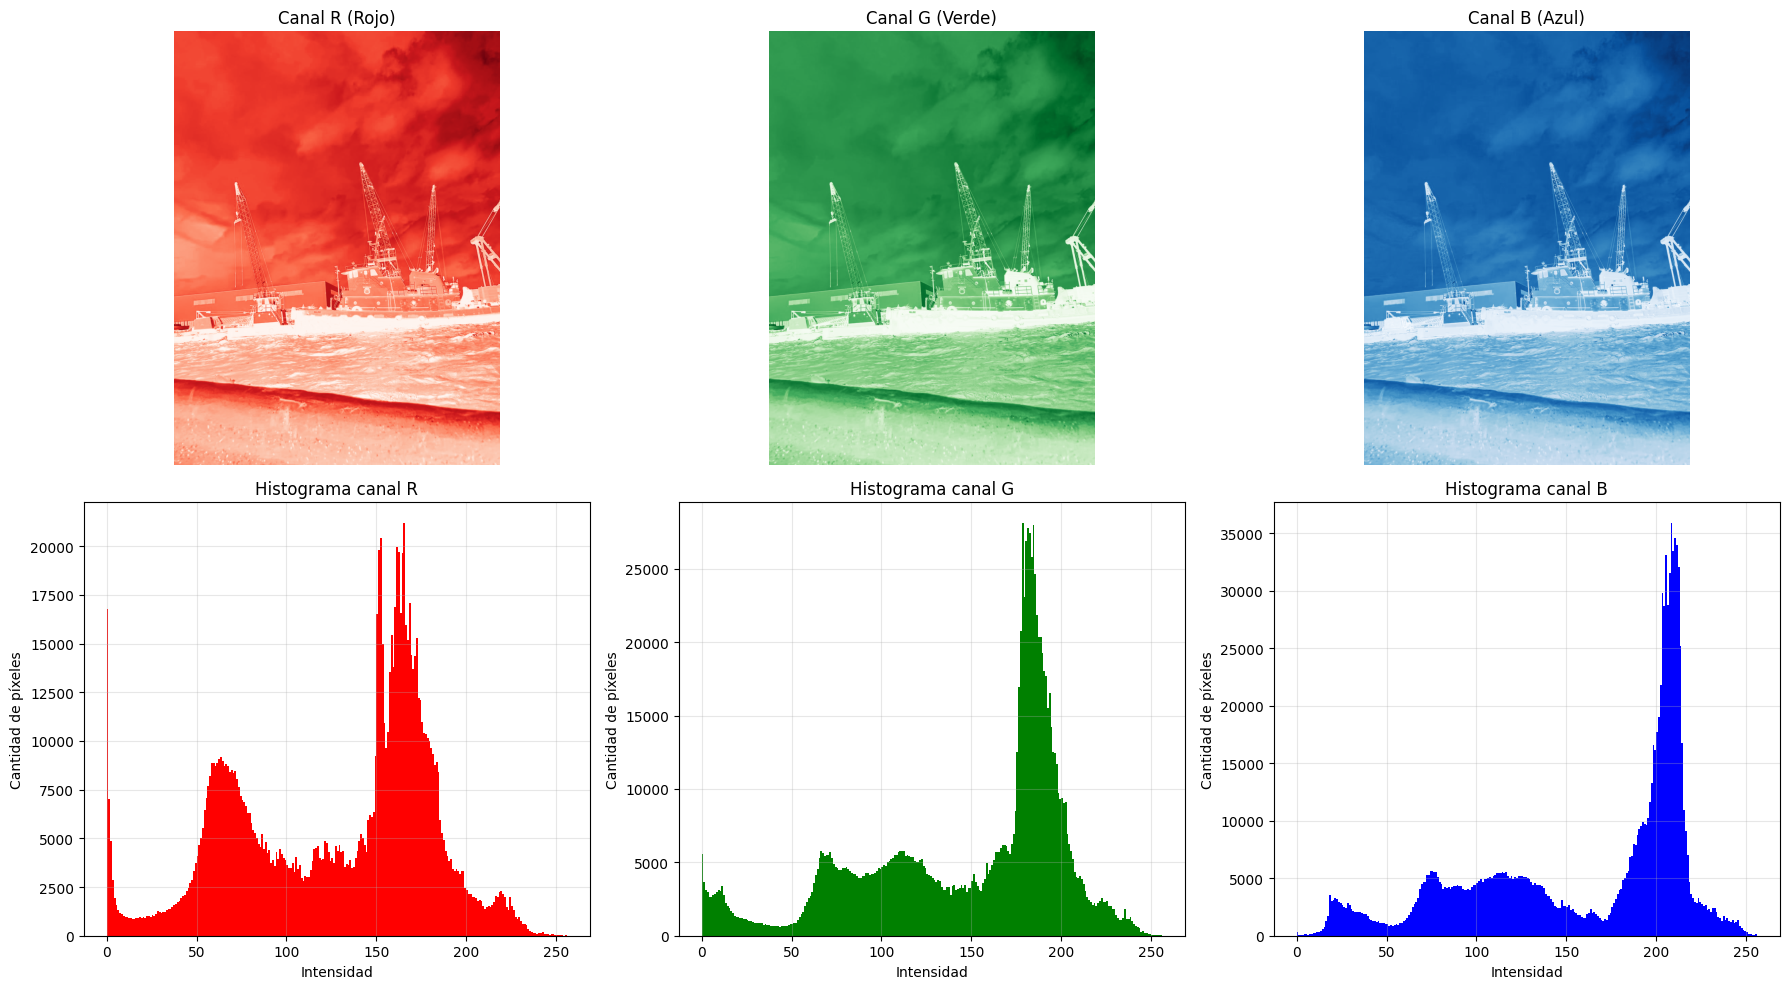

Canal R -> shape: (1280, 960) rango: 0 - 255
Canal G -> shape: (1280, 960) rango: 0 - 255
Canal B -> shape: (1280, 960) rango: 0 - 255

La imagen NO tiene canal alfa (es RGB puro, 3 canales).


In [12]:
# Separar canales si la imagen es a color
if canales >= 3:
    canal_r = imagen_plana[:, :, 0]
    canal_g = imagen_plana[:, :, 1]
    canal_b = imagen_plana[:, :, 2]

    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    # Fila 1: imagen de cada canal
    axes[0, 0].imshow(canal_r, cmap="Reds");   axes[0, 0].set_title("Canal R (Rojo)");  axes[0, 0].axis("off")
    axes[0, 1].imshow(canal_g, cmap="Greens"); axes[0, 1].set_title("Canal G (Verde)"); axes[0, 1].axis("off")
    axes[0, 2].imshow(canal_b, cmap="Blues");  axes[0, 2].set_title("Canal B (Azul)");  axes[0, 2].axis("off")

    # Fila 2: histograma de cada canal
    axes[1, 0].hist(canal_r.ravel(), bins=256, range=(0, 256), color="red")
    axes[1, 0].set_title("Histograma canal R")
    axes[1, 1].hist(canal_g.ravel(), bins=256, range=(0, 256), color="green")
    axes[1, 1].set_title("Histograma canal G")
    axes[1, 2].hist(canal_b.ravel(), bins=256, range=(0, 256), color="blue")
    axes[1, 2].set_title("Histograma canal B")
    for ax in axes[1]:
        ax.set_xlabel("Intensidad"); ax.set_ylabel("Cantidad de píxeles"); ax.grid(alpha=0.3)

    plt.tight_layout(); plt.show()

    print("Canal R -> shape:", canal_r.shape, "rango:", canal_r.min(), "-", canal_r.max())
    print("Canal G -> shape:", canal_g.shape, "rango:", canal_g.min(), "-", canal_g.max())
    print("Canal B -> shape:", canal_b.shape, "rango:", canal_b.min(), "-", canal_b.max())
else:
    print("La imagen es de un solo canal (escala de grises).")

# Canal alfa (transparencia), si existe (4 canales)
if canales == 4:
    canal_alfa = imagen_plana[:, :, 3]
    print("\n¡La imagen tiene 4 canales! El 4º es el canal ALFA (transparencia).")
    plt.figure(figsize=(8, 5)); plt.imshow(canal_alfa, cmap="gray")
    plt.title("Canal Alfa (transparencia) — 255 = opaco"); plt.axis("off"); plt.show()
else:
    print("\nLa imagen NO tiene canal alfa (es RGB puro, 3 canales).")


# 1.3 Histograma Imagen plana

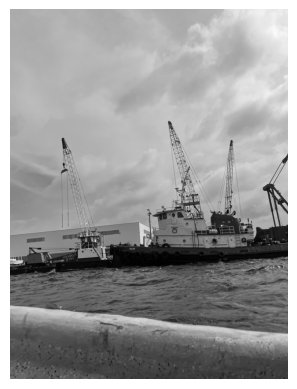

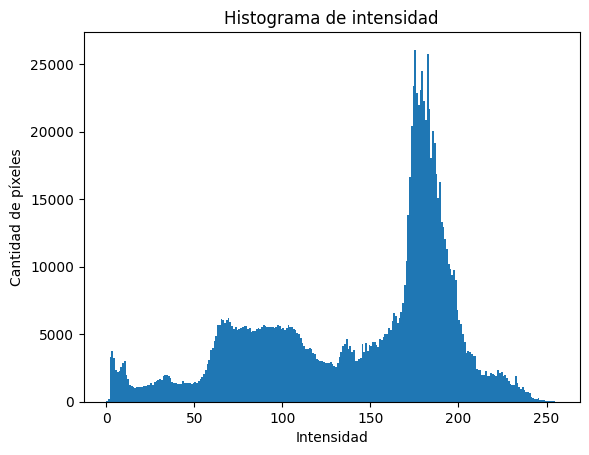

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Cargar imagen
imagen = Image.open(RUTA_PLANA).convert("L")

# Convertir a numpy
imagen_array = np.array(imagen)

# Mostrar imagen
plt.imshow(imagen_array, cmap="gray")
plt.axis("off")
plt.show()

# Histograma
plt.hist(imagen_array.ravel(), bins=256, range=(0, 256))

plt.xlabel("Intensidad")
plt.ylabel("Cantidad de píxeles")
plt.title("Histograma de intensidad")
plt.show()


## 1.4 Modelamiento de ruido de una región de 50x50 píxeles - Histograma

Se convierte la imagen plana (`mar.jpeg`) a **escala de grises** usando la luminancia **Y = 0.2989·R + 0.5870·G + 0.1140·B**. Luego se toma una **región homogénea de 50x50 píxeles** en la esquina superior izquierda, que cae sobre el **cielo nublado**, y se calcula su **histograma**. La región se marca en rojo sobre la imagen completa y al lado se muestra ampliada en escala de grises.

En una zona uniforme de la imagen, la variación de intensidades se debe principalmente al **ruido**. Para describirlo se calculan cuatro parámetros:

- **Media (μ):** intensidad promedio de la región; es el centro de la campana y representa la señal.
- **Desviación estándar (σ):** ancho de la campana; mide la cantidad de ruido.
- **Asimetría:** indica si la campana es simétrica (≈ 0, ruido **gaussiano**) o tiene una cola hacia un lado (positiva = cola a la derecha, negativa = cola a la izquierda).
- **SNR (μ/σ):** relación señal/ruido; mientras mayor sea, más limpia es la imagen.

**Resultados:**

| Parámetro | Valor |
|---|---|
| Media (μ) | 171.28 |
| Desviación estándar (σ) | 0.97 |
| Asimetría | 0.321 |
| SNR (μ/σ) | 177.25 |

La asimetría es baja (0.321), así que el histograma tiene forma de **campana casi simétrica**, con una **leve cola hacia la derecha** (hacia intensidades más claras). El ruido se puede modelar en buena medida como **gaussiano**, como se espera en una foto de cámara. La pequeña asimetría puede deberse a variaciones suaves de brillo en las nubes. La σ es menor a 1 nivel de gris y la SNR es muy alta, lo que indica una región con **muy poco ruido**. Parte de esta uniformidad también puede venir de la **compresión JPEG**, que suaviza las zonas planas.


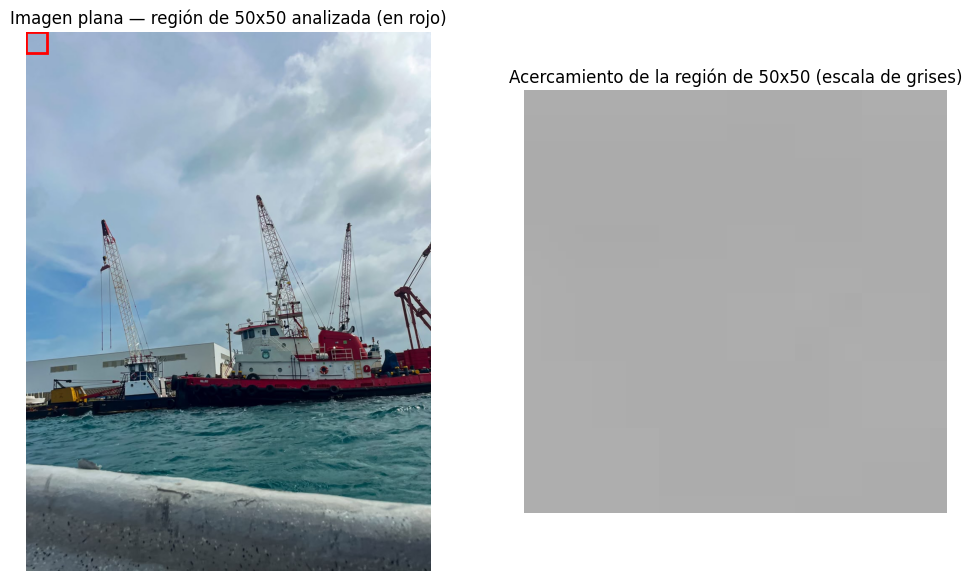

========== RUIDO EN LA REGIÓN ==========

Media (mu):                  171.28
Desviación estándar (sigma): 0.97
Asimetría:                   0.321
SNR (mu/sigma):              177.25


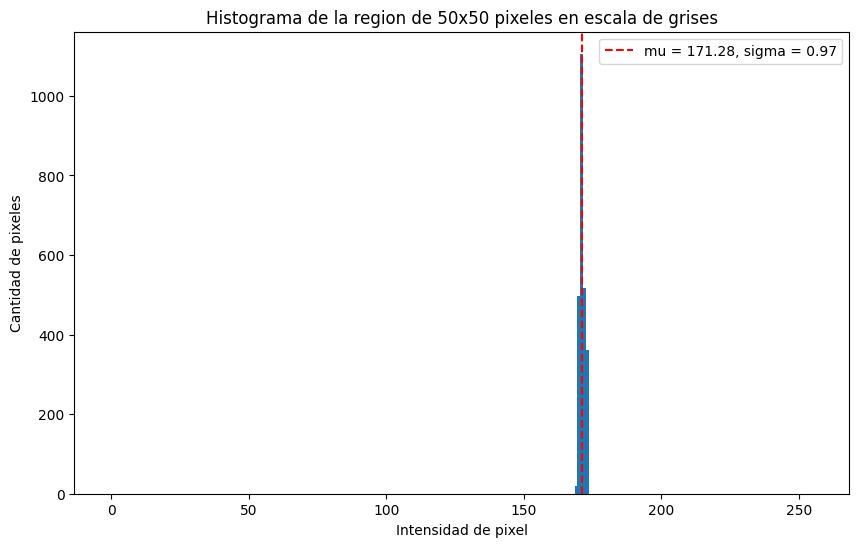

In [16]:
# ============================================================
# HISTOGRAMA DE UNA REGIÓN DE 50x50 PÍXELES EN ESCALA DE GRISES
# ============================================================

# Librerías:
# - numpy: para trabajar la imagen como matriz numérica
# - matplotlib: para mostrar la imagen y graficar el histograma
# - PIL (Pillow): para abrir la imagen
import numpy as librerianumpy
import matplotlib.pyplot as libreriaparagraficar
import matplotlib.patches as rectangulos
from PIL import Image

# Ruta de la imagen plana dentro del proyecto (ruta relativa a la carpeta del notebook)
ruta_imagen = "imagenes/imagen plana/mar.jpeg"

# Abrir la imagen con PIL
mi_imagen = Image.open(ruta_imagen)


# Función que calcula el histograma de una imagen de 8 bits (0 a 255):
# para cada intensidad i cuenta cuántos píxeles tienen exactamente ese valor
def calcular_histograma(imagen):
    histograma = []  # cantidad de píxeles por cada intensidad
    xticks = []      # valores de intensidad (eje X): 0, 1, 2, ..., 255
    for i in range(0, 256):
        xticks.append(i)
        histograma.append(librerianumpy.count_nonzero(imagen == i))
    return histograma, xticks


# Convertir la imagen a matriz numérica -> forma (alto, ancho, canales)
datos_numericos_de_imagen = librerianumpy.asarray(mi_imagen)

# Convertir a escala de grises (luminancia Y) con los pesos estándar:
# Y = 0.2989*R + 0.5870*G + 0.1140*B
# [..., :3] toma solo los canales R, G, B (ignora el canal alfa si existe)
# Se divide entre 255 para normalizar los valores al rango 0-1
imagen_Y = librerianumpy.dot(datos_numericos_de_imagen[..., :3] / 255, [0.2989, 0.5870, 0.1140])

# Usar la imagen en escala de grises ya calculada (imagen_Y)
imagen_gris_completa = imagen_Y

# Seleccionar una región de 50x50 píxeles HOMOGÉNEA:
# esquina superior izquierda (filas 0 a 49 y columnas 0 a 49), que cae sobre el cielo nublado
fila_inicio, columna_inicio = 0, 0
region_50x50_gris = imagen_gris_completa[fila_inicio:fila_inicio + 50, columna_inicio:columna_inicio + 50]

# Mostrar la imagen completa marcando en rojo la región seleccionada,
# y al lado un acercamiento de la región en escala de grises
figura, ejes = libreriaparagraficar.subplots(1, 2, figsize=(12, 7))

ejes[0].imshow(mi_imagen)
ejes[0].add_patch(rectangulos.Rectangle((columna_inicio, fila_inicio), 50, 50, edgecolor="red", facecolor="none", linewidth=2))
ejes[0].set_title("Imagen plana — región de 50x50 analizada (en rojo)")
ejes[0].axis("off")

ejes[1].imshow(region_50x50_gris, cmap="gray", vmin=0, vmax=1)
ejes[1].set_title("Acercamiento de la región de 50x50 (escala de grises)")
ejes[1].axis("off")

libreriaparagraficar.show()

# Escalar los valores de píxel de 0-1 a 0-255 y luego convertir a uint8 (enteros de 8 bits)
region_50x50_escalada_uint8 = (region_50x50_gris * 255).astype(librerianumpy.uint8)

# Para cuantificar qué tan achatada o qué tan alargada es la campana gaussiana
# se usan los parámetros sigma (desviación estándar) y mu (media)

# Se pasa la región a decimales (float) para que las operaciones no se desborden en uint8
region_float = region_50x50_escalada_uint8.astype(librerianumpy.float64)

# Media (mu): centro de la campana = intensidad promedio (señal) de la región
mu = region_float.mean()

# Desviación estándar (sigma): ancho de la campana = cantidad de ruido
sigma = region_float.std()

# Asimetría: 0 = campana simétrica (ruido gaussiano);
# positiva = cola a la derecha, negativa = cola a la izquierda
asimetria = librerianumpy.mean(((region_float - mu) / sigma) ** 3)

# Relación señal/ruido (SNR): cuántas veces la señal es mayor que el ruido
snr = mu / sigma

print("========== RUIDO EN LA REGIÓN ==========\n")
print(f"Media (mu):                  {mu:.2f}")
print(f"Desviación estándar (sigma): {sigma:.2f}")
print(f"Asimetría:                   {asimetria:.3f}")
print(f"SNR (mu/sigma):              {snr:.2f}")

# Calcular el histograma de la región seleccionada
histograma_region, xticks_region = calcular_histograma(region_50x50_escalada_uint8)

# Graficar el histograma como gráfico de barras
libreriaparagraficar.figure(figsize=(10, 6))
libreriaparagraficar.bar(xticks_region, histograma_region, width=1.0)
# Línea vertical roja en la media (centro de la campana)
libreriaparagraficar.axvline(mu, color="red", linestyle="--", label=f"mu = {mu:.2f}, sigma = {sigma:.2f}")
libreriaparagraficar.title('Histograma de la region de 50x50 pixeles en escala de grises')
libreriaparagraficar.xlabel('Intensidad de pixel')
libreriaparagraficar.ylabel('Cantidad de pixeles')
libreriaparagraficar.legend()
libreriaparagraficar.show()


## 1.5 Análisis Estadístico del Ruido en la Imagen Plana con la Prueba de Kolmogorov-Smirnov (K-S)

La prueba K-S compara la distribución acumulada (CDF) de los 2500 píxeles de la región de 50x50 (escala de grises, 8 bits) con dos distribuciones teóricas de ruido:

- **Gaussiana:** usa la media (μ) y la desviación estándar (σ) de la región.
- **Uniforme:** ajustada al rango real de la región (mínimo a máximo), no al rango completo 0–255.

**Interpretación (α = 0.05):**

- **Estadístico D:** es la distancia máxima entre la CDF de los datos y la teórica. La distribución con **menor D** es la que mejor describe el ruido.
- **p-valor ≥ 0.05:** no se rechaza la hipótesis nula, así que el ruido **podría** seguir esa distribución.
- **p-valor < 0.05:** se rechaza, así que el ruido es **significativamente diferente** de esa distribución.

**Resultados:**

| Distribución | Estadístico D | p-valor | Resultado |
|---|---|---|---|
| Gaussiana | 0.2633 | ≈ 0.0000 | Se rechaza |
| Uniforme | 0.2940 | ≈ 0.0000 | Se rechaza |

Las dos distribuciones se rechazan formalmente. Esto se debe a que la región solo contiene **5 niveles de gris distintos (169 a 173)**, por lo que su CDF avanza en escalones y no se ajusta exactamente a ninguna curva continua. Además, con 2500 píxeles la prueba es muy sensible y cualquier diferencia pequeña da un p-valor prácticamente 0.

Aun así, la **Gaussiana tiene menor D (0.2633 < 0.2940)**, así que es la distribución que **mejor describe el ruido** de la imagen plana. Esto coincide con la baja asimetría obtenida en la sección 1.4, que mostró una campana casi simétrica.

> **Nota:** los píxeles son enteros de 0 a 255 y μ y σ se estiman con los mismos datos que se prueban. Por eso el p-valor es aproximado, y la comparación de D es el criterio más confiable.


In [15]:
# ============================================================
# PRUEBA K-S: ¿EL RUIDO DE LA IMAGEN PLANA ES GAUSSIANO O UNIFORME?
# ============================================================

# Librería:
# - scipy.stats: para la prueba de Kolmogorov-Smirnov (K-S)
from scipy import stats

# Valores de la región de 50x50 (0 a 255) como un arreglo 1D (2500 valores)
# Se usa region_float para trabajar con los mismos datos de mu y sigma
valores_region = region_float.flatten()

# Nivel de significancia: si p-valor < 0.05 se rechaza que los datos
# sigan la distribución que se está probando
alfa = 0.05

# --- Prueba contra una distribución Gaussiana ---
# Se usan el mismo mu y sigma calculados antes para la campana gaussiana
estadistico_normal, p_valor_normal = stats.kstest(valores_region, "norm", args=(mu, sigma))

print("\n========== PRUEBA K-S ==========\n")
print("Contra distribución Gaussiana:")
print(f" Estadístico D: {estadistico_normal:.4f}")
print(f" P-valor:       {p_valor_normal:.4f}")
print(" ->", "Se rechaza que sea gaussiana" if p_valor_normal < alfa else "Compatible con ruido gaussiano")

# --- Prueba contra una distribución Uniforme ---
# Aunque la imagen es de 8 bits (0 a 255), la región solo ocupa una parte de ese rango,
# así que la uniforme se ajusta al rango real de la región:
# loc = valor mínimo, scale = valor máximo - valor mínimo
minimo_region = valores_region.min()
maximo_region = valores_region.max()
estadistico_uniforme, p_valor_uniforme = stats.kstest(valores_region, "uniform", args=(minimo_region, maximo_region - minimo_region))

print("\nContra distribución Uniforme:")
print(f" Estadístico D: {estadistico_uniforme:.4f}")
print(f" P-valor:       {p_valor_uniforme:.4f}")
print(" ->", "Se rechaza que sea uniforme" if p_valor_uniforme < alfa else "Compatible con ruido uniforme")

# Cuanto menor sea D, más se parece la distribución de los datos a la teórica
print("\nDistribución que mejor se ajusta:", "Gaussiana" if estadistico_normal < estadistico_uniforme else "Uniforme")



========== PRUEBA K-S ==========

Contra distribución Gaussiana:
 Estadístico D: 0.2633
 P-valor:       0.0000
 -> Se rechaza que sea gaussiana

Contra distribución Uniforme:
 Estadístico D: 0.2940
 P-valor:       0.0000
 -> Se rechaza que sea uniforme

Distribución que mejor se ajusta: Gaussiana


# Parte 2 - Resonancia magnética.


Dataset.file_meta -------------------------------
(0002,0000) File Meta Information Group Length  UL: 212
(0002,0001) File Meta Information Version       OB: b'\x00\x01'
(0002,0002) Media Storage SOP Class UID         UI: MR Image Storage
(0002,0003) Media Storage SOP Instance UID      UI: 1.2.840.113619.2.207.6945.297264.11272.1238998881.891
(0002,0010) Transfer Syntax UID                 UI: Explicit VR Little Endian
(0002,0012) Implementation Class UID            UI: 1.2.276.0.7230010.3.0.3.5.5
(0002,0013) Implementation Version Name         SH: 'OFFIS_DCMTK_355'
(0002,0016) Source Application Entity Title     AE: 'BASIX'
-------------------------------------------------
(0008,0005) Specific Character Set              CS: 'ISO_IR 100'
(0008,0008) Image Type                          CS: ['ORIGINAL', 'PRIMARY', 'OTHER']
(0008,0016) SOP Class UID                       UI: MR Image Storage
(0008,0018) SOP Instance UID                    UI: 1.2.840.113619.2.207.6945.297264.11272.1238998

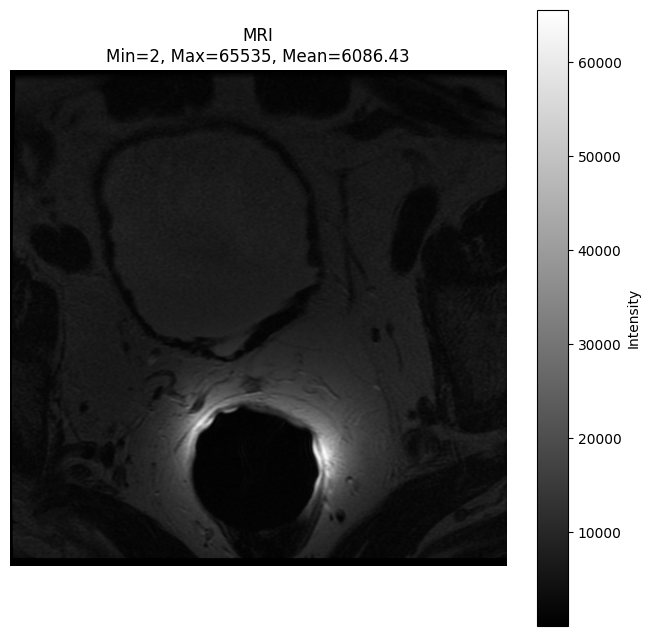

In [27]:
def process_dicom(path):
    """
    Lee un archivo DICOM, extrae e imprime sus metadatos principales,
    y genera estadísticas y visualizaciones básicas de la imagen.
    """
    dicom = pydicom.dcmread(path)
    print(dicom)
    print("\n========== DICOM HEADER ==========\n")

    fields = [
        "Modality", "Manufacturer", "ManufacturerModelName", "MagneticFieldStrength",
        "Rows", "Columns", "SamplesPerPixel", "PhotometricInterpretation",
        "BitsAllocated", "BitsStored", "HighBit", "PixelRepresentation",
        "PixelSpacing", "SliceThickness", "WindowCenter", "WindowWidth",
        "RescaleIntercept", "RescaleSlope", "AcquisitionMatrix",
        "RepetitionTime", "EchoTime", "FlipAngle", "InversionTime",
        "SequenceName", "ScanningSequence", "SequenceVariant", "PixelBandwidth"
    ]

    for field in fields:
        if hasattr(dicom, field):
            print(f"{field}: {getattr(dicom, field)}")

    pixel_array = dicom.pixel_array
    print("\n========== PIXEL ARRAY ==========\n")
    print("Shape:", pixel_array.shape)
    print("dtype:", pixel_array.dtype)
    print("Número de píxeles:", pixel_array.size)

    pixel_min, pixel_max = pixel_array.min(), pixel_array.max()
    pixel_mean, pixel_std = pixel_array.mean(), pixel_array.std()

    print("\n========== INTENSIDADES ==========\n")
    print("Mínimo:", pixel_min)
    print("Máximo:", pixel_max)
    print("Media:", pixel_mean)
    print("Desviación estándar:", pixel_std)

    print("\nPercentiles:")
    for p in [0, 1, 5, 25, 50, 75, 95, 99, 100]:
        print(f"{p}%: {np.percentile(pixel_array, p)}")

    print("\n========== EJEMPLO DE PIXELES ==========\n")
    print(pixel_array[:10, :10])

    plt.figure(figsize=(8, 8))
    plt.imshow(pixel_array, cmap="gray")
    plt.colorbar(label="Intensity")
    plt.title(f"MRI\nMin={pixel_min}, Max={pixel_max}, Mean={pixel_mean:.2f}")
    plt.axis("off")
    plt.show()

# Ejecución de la inspección inicial usando el path unificado
process_dicom("imagenes/resonancia magentica/MRI01.dcm")

## 2.1 Anonimización del archivo DICOM (resonancia magnética)

Antes de compartir o entregar la imagen, se eliminan del encabezado DICOM los datos que permiten identificar al paciente: nombre, ID, fecha de nacimiento, edad, peso, médicos, números del estudio, fechas del examen y tags privados del fabricante. Los parámetros técnicos de adquisición y la imagen (`Pixel Data`) se conservan intactos.


In [28]:
import pydicom

# ============================================================
# RUTAS DE ENTRADA Y SALIDA
# ============================================================
filepath = "imagenes/resonancia magentica/MRI01.dcm"
output_path = "imagenes/resonancia magentica/MRI01_anonimo.dcm"

# ============================================================
# LEER DICOM
# ============================================================
ds = pydicom.dcmread(filepath)

# ============================================================
# DATOS DE IDENTIFICACIÓN DEL PACIENTE
# ============================================================
ds.PatientName = "ANONYMOUS"
ds.PatientID = "ANONYMOUS"
ds.PatientBirthDate = ""
ds.PatientSex = ""

# ============================================================
# OTROS DATOS PERSONALES Y CLÍNICOS DEL PACIENTE
# ============================================================
ds.OtherPatientIDs = ""
ds.OtherPatientNames = ""
ds.PatientAddress = ""
ds.PatientTelephoneNumbers = ""
ds.PatientComments = ""
ds.AdditionalPatientHistory = ""

# ============================================================
# PERSONAL MÉDICO E INSTITUCIÓN
# ============================================================
ds.ReferringPhysicianName = ""
ds.NameOfPhysiciansReadingStudy = ""
ds.OperatorsName = ""
ds.InstitutionName = ""
ds.InstitutionAddress = ""

# ============================================================
# TAGS PRIVADOS DEL FABRICANTE
# ============================================================
ds.remove_private_tags()

# ============================================================
# GUARDAR ARCHIVO ANONIMIZADO
# ============================================================
ds.save_as(output_path)

print("Archivo anonimizado:")
print(output_path)


Archivo anonimizado:
imagenes/resonancia magentica/MRI01_anonimo.dcm


## 2.2 Verificación de la anonimización

Se comparan los campos del archivo original con los del archivo anonimizado para comprobar que los datos del paciente, del personal médico y de la institución fueron reemplazados o vaciados, y que se eliminaron los tags privados del fabricante.


In [29]:
import pydicom

# ============================================================
# VERIFICAR ANONIMIZACIÓN: ORIGINAL vs ANONIMIZADO
# ============================================================
original = pydicom.dcmread("imagenes/resonancia magentica/MRI01.dcm")
anonimo = pydicom.dcmread("imagenes/resonancia magentica/MRI01_anonimo.dcm")

# Campos agrupados según a quién pertenecen los datos
grupos = {
    "DATOS DEL PACIENTE": [
        "PatientName", "PatientID", "PatientBirthDate", "PatientSex",
        "OtherPatientIDs", "OtherPatientNames", "PatientAddress",
        "PatientTelephoneNumbers", "PatientComments", "AdditionalPatientHistory",
    ],
    "DATOS DEL PERSONAL MÉDICO": [
        "ReferringPhysicianName", "NameOfPhysiciansReadingStudy", "OperatorsName",
    ],
    "DATOS DE LA INSTITUCIÓN": [
        "InstitutionName", "InstitutionAddress",
    ],
}

for grupo, campos in grupos.items():
    print(f"\n========== {grupo} ==========\n")
    print(f"{'CAMPO':<32}{'ORIGINAL':<25}{'ANONIMIZADO'}")
    print("-" * 75)
    for campo in campos:
        antes = str(original.get(campo, "(no existe)"))
        despues = str(anonimo.get(campo, "(no existe)"))
        print(f"{campo:<32}{antes:<25}{despues}")

# ============================================================
# TAGS PRIVADOS DEL FABRICANTE
# ============================================================
print("\n========== TAGS PRIVADOS DEL FABRICANTE ==========\n")
privados_antes = sum(1 for e in original if e.tag.is_private)
privados_despues = sum(1 for e in anonimo if e.tag.is_private)
print(f"Original: {privados_antes} | Anonimizado: {privados_despues}")



========== DATOS DEL PACIENTE ==========

CAMPO                           ORIGINAL                 ANONIMIZADO
---------------------------------------------------------------------------
PatientName                     002                      ANONYMOUS
PatientID                       680710                   ANONYMOUS
PatientBirthDate                19380722                 
PatientSex                      M                        
OtherPatientIDs                 (no existe)              
OtherPatientNames               (no existe)              
PatientAddress                  (no existe)              
PatientTelephoneNumbers         (no existe)              
PatientComments                 (no existe)              
AdditionalPatientHistory                                 

========== DATOS DEL PERSONAL MÉDICO ==========

CAMPO                           ORIGINAL                 ANONIMIZADO
---------------------------------------------------------------------------
ReferringPhysicianN

## 2.3 Histrograma Resonancia magnetica

Tipo de dato: uint16
Tamaño: (512, 512)
Valor mínimo: 2
Valor máximo: 65535
Cantidad de valores diferentes: 6512


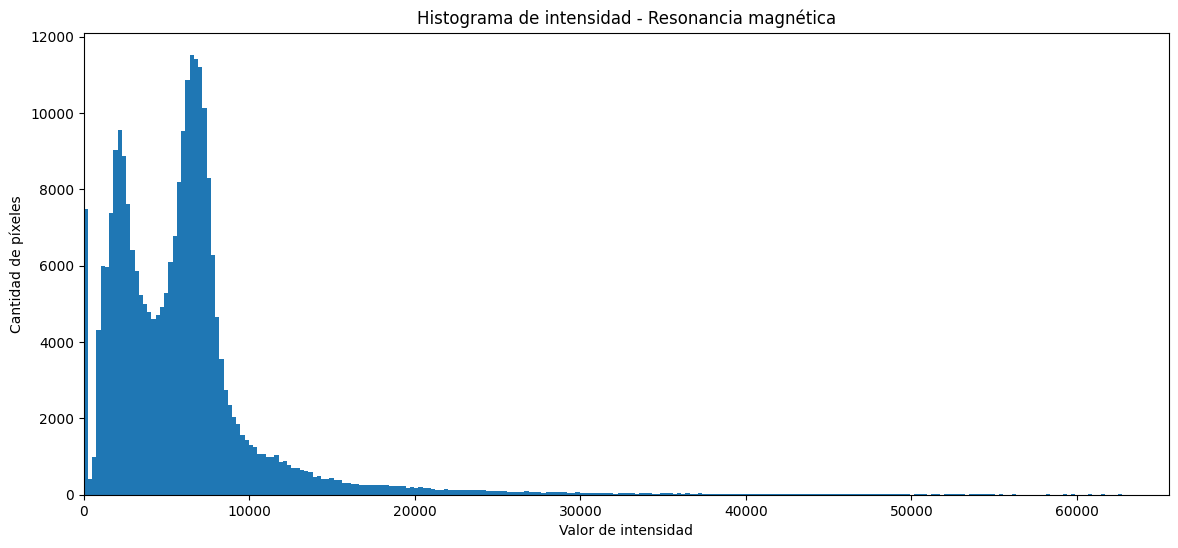

In [30]:
import pydicom
import numpy as np
import matplotlib.pyplot as plt

# Cargar DICOM
ds = pydicom.dcmread("imagenes/resonancia magentica/MRI01.dcm")
imagen = ds.pixel_array

# Obtener cada valor de intensidad y su cantidad de píxeles
valores, cantidad = np.unique(imagen, return_counts=True)

# Información
print("Tipo de dato:", imagen.dtype)
print("Tamaño:", imagen.shape)
print("Valor mínimo:", imagen.min())
print("Valor máximo:", imagen.max())
print("Cantidad de valores diferentes:", len(valores))

# Agrupar las intensidades en 256 intervalos (bins)
cantidad_bins, bordes = np.histogram(imagen, bins=256, range=(0, 65536))

# Graficar histograma
plt.figure(figsize=(14, 6))

plt.bar(
    bordes[:-1],
    cantidad_bins,
    width=bordes[1] - bordes[0],
    align="edge"
)

plt.xlabel("Valor de intensidad")
plt.ylabel("Cantidad de píxeles")
plt.title("Histograma de intensidad - Resonancia magnética")

plt.xlim(0, 65535)

plt.show()


## 2.4 Modelamiento de ruido en la resonancia magnética (región de 50x50 píxeles)

Se analiza el ruido de la resonancia (`MRI01.dcm`) con el mismo procedimiento de la imagen plana, con tres diferencias:

- La resonancia ya está en **escala de grises** (1 canal), así que no se convierte de RGB a Y.
- Es una imagen de **16 bits** (0 a 65535), por lo que el histograma agrupa las intensidades en **100 intervalos** en lugar de 256 niveles.
- La región de 50x50 se toma dentro de la **vejiga** (filas 150–199, columnas 200–249), una zona de tejido **uniforme** donde la variación de intensidad se debe al ruido. La esquina superior izquierda no sirve porque contiene tejido y bordes.

**Resultados:**

| Parámetro | Valor |
|---|---|
| Media (μ) | 7125.38 |
| Desviación estándar (σ) | 663.81 |
| Asimetría | −0.044 |
| SNR (μ/σ) | 10.73 |

El histograma tiene forma de **campana simétrica** y se ajusta a la curva gaussiana teórica. En resonancia magnética el ruido es teóricamente **Rician**, pero cuando la señal es alta (SNR > 3) se comporta prácticamente como **gaussiano**, que es lo que se observa aquí. En zonas sin señal (fondo oscuro), el ruido Rician tiende a una distribución **Rayleigh**, que es asimétrica. Identificar el tipo de ruido permite elegir el filtro adecuado para corregirlo.


Shape: (512, 512)
dtype original: uint16 | BitsStored: 16
Mínimo: 2.0 | Máximo: 65535.0


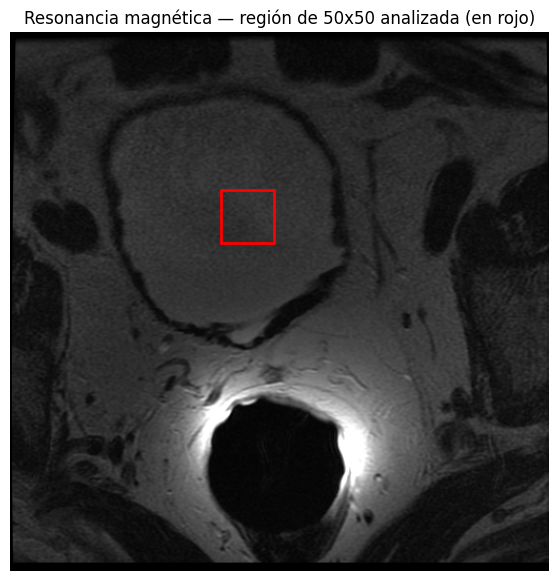


========== RUIDO EN LA REGIÓN ==========

Media (mu):                 7125.38
Desviación estándar (sigma): 663.81
Asimetría:                  -0.044
SNR (mu/sigma):             10.73


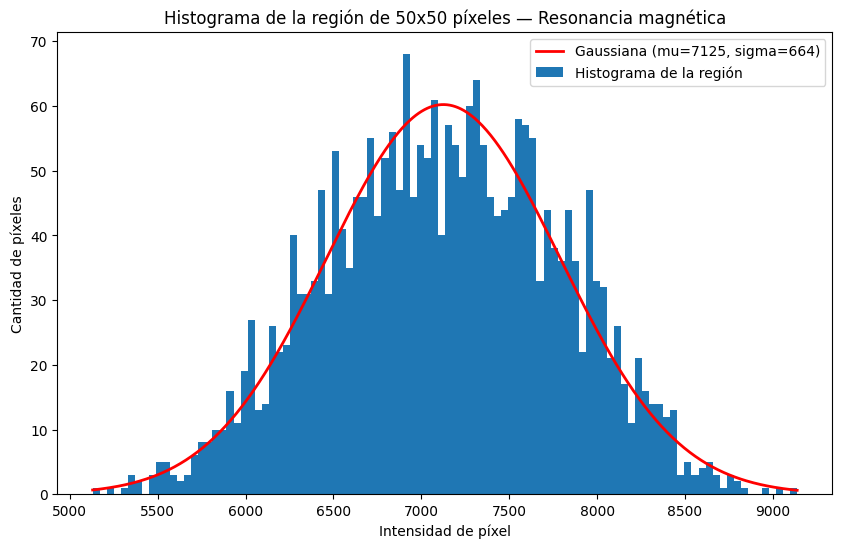

In [1]:
# ============================================================
# ANÁLISIS DE RUIDO EN LA RESONANCIA MAGNÉTICA (REGIÓN DE 50x50 PÍXELES)
# ============================================================

# Librerías:
# - numpy: para trabajar la imagen como matriz numérica
# - matplotlib: para mostrar la imagen y graficar el histograma
# - pydicom: para leer el archivo DICOM de la resonancia
import numpy as librerianumpy
import matplotlib.pyplot as libreriaparagraficar
import matplotlib.patches as rectangulos
import pydicom

# Ruta de la resonancia dentro del proyecto
ruta_imagen = "imagenes/resonancia magentica/MRI01.dcm"

# Leer el DICOM y extraer la matriz de píxeles
# (la resonancia ya viene en escala de grises: 1 solo canal, no hace falta convertir RGB -> Y)
dicom = pydicom.dcmread(ruta_imagen)
imagen_gris_completa = dicom.pixel_array.astype(librerianumpy.float64)

print("Shape:", imagen_gris_completa.shape)
print("dtype original:", dicom.pixel_array.dtype, "| BitsStored:", dicom.BitsStored)
print("Mínimo:", imagen_gris_completa.min(), "| Máximo:", imagen_gris_completa.max())


# Función que calcula el histograma de la región.
# A diferencia de la imagen plana (8 bits, 0 a 255), la resonancia es de 16 bits
# (valores de 0 a 65535), así que el recorrido va desde el valor mínimo
# hasta el máximo de la región, agrupando las intensidades en "bins" (intervalos)
def calcular_histograma(imagen, numero_bins=100):
    histograma = []  # cantidad de píxeles en cada intervalo
    xticks = []      # centro de cada intervalo (eje X)
    bordes = librerianumpy.linspace(imagen.min(), imagen.max(), numero_bins + 1)
    for i in range(numero_bins):
        xticks.append((bordes[i] + bordes[i + 1]) / 2)
        if i == numero_bins - 1:
            # el último intervalo incluye el valor máximo
            histograma.append(librerianumpy.count_nonzero((imagen >= bordes[i]) & (imagen <= bordes[i + 1])))
        else:
            histograma.append(librerianumpy.count_nonzero((imagen >= bordes[i]) & (imagen < bordes[i + 1])))
    return histograma, xticks, bordes[1] - bordes[0]


# Seleccionar una región de 50x50 píxeles HOMOGÉNEA.
# Se usa el interior de la vejiga (filas 150-199, columnas 200-249): es una zona de
# tejido uniforme, así que la variación de intensidad que haya se debe al ruido.
# (La esquina superior izquierda NO sirve aquí porque tiene tejido y bordes)
fila_inicio, columna_inicio = 150, 200
region_50x50_gris = imagen_gris_completa[fila_inicio:fila_inicio + 50, columna_inicio:columna_inicio + 50]

# Mostrar la resonancia marcando en rojo la región seleccionada
figura, eje = libreriaparagraficar.subplots(figsize=(7, 7))
eje.imshow(imagen_gris_completa, cmap="gray", vmax=librerianumpy.percentile(imagen_gris_completa, 99.5))
eje.add_patch(rectangulos.Rectangle((columna_inicio, fila_inicio), 50, 50, edgecolor="red", facecolor="none", linewidth=2))
eje.set_title("Resonancia magnética — región de 50x50 analizada (en rojo)")
eje.axis("off")
libreriaparagraficar.show()

# Parámetros de la campana gaussiana:
# mu (media) = dónde está el centro de la campana
# sigma (desviación estándar) = qué tan ancha es (más sigma = más ruido)
mu = region_50x50_gris.mean()
sigma = region_50x50_gris.std()

# Asimetría (skewness): 0 = campana simétrica (gaussiana);
# un valor positivo grande = cola hacia la derecha (típico del ruido Rician/Rayleigh)
asimetria = librerianumpy.mean(((region_50x50_gris - mu) / sigma) ** 3)

# Relación señal/ruido (SNR) de la región = mu / sigma
snr = mu / sigma

print("\n========== RUIDO EN LA REGIÓN ==========\n")
print(f"Media (mu):                 {mu:.2f}")
print(f"Desviación estándar (sigma): {sigma:.2f}")
print(f"Asimetría:                  {asimetria:.3f}")
print(f"SNR (mu/sigma):             {snr:.2f}")

# Calcular el histograma de la región seleccionada
histograma_region, xticks_region, ancho_bin = calcular_histograma(region_50x50_gris)

# Curva gaussiana teórica con el mismo mu y sigma, escalada al número de píxeles,
# para comparar visualmente con el histograma real
x = librerianumpy.linspace(region_50x50_gris.min(), region_50x50_gris.max(), 500)
gaussiana = (1 / (sigma * librerianumpy.sqrt(2 * librerianumpy.pi))) * librerianumpy.exp(-0.5 * ((x - mu) / sigma) ** 2)
gaussiana = gaussiana * region_50x50_gris.size * ancho_bin

# Graficar el histograma como gráfico de barras junto con la gaussiana teórica
libreriaparagraficar.figure(figsize=(10, 6))
libreriaparagraficar.bar(xticks_region, histograma_region, width=ancho_bin, label="Histograma de la región")
libreriaparagraficar.plot(x, gaussiana, color="red", linewidth=2, label=f"Gaussiana (mu={mu:.0f}, sigma={sigma:.0f})")
libreriaparagraficar.title("Histograma de la región de 50x50 píxeles — Resonancia magnética")
libreriaparagraficar.xlabel("Intensidad de píxel")
libreriaparagraficar.ylabel("Cantidad de píxeles")
libreriaparagraficar.legend()
libreriaparagraficar.show()


## 2.5 Análisis Estadístico del Ruido en la Resonancia Magnética con la Prueba de Kolmogorov-Smirnov (K-S)

La prueba K-S compara la distribución acumulada (CDF) de los 2500 píxeles de la región homogénea de 50x50 (interior de la vejiga, 16 bits) con tres distribuciones teóricas de ruido:

- **Gaussiana:** usa la media (μ) y la desviación estándar (σ) de la región.
- **Uniforme:** ajustada al rango real de la región (mínimo a máximo), no a 0–255.
- **Rician:** el modelo teórico del ruido en resonancia, porque la imagen es la magnitud de una señal compleja. Sus parámetros se ajustan a los datos. Con SNR alto se parece mucho a una gaussiana.

**Interpretación (α = 0.05):**

- **Estadístico D:** es la distancia máxima entre la CDF de los datos y la teórica. La distribución con **menor D** es la que mejor describe el ruido.
- **p-valor > 0.05:** no se rechaza la hipótesis nula, así que el ruido **podría** seguir esa distribución.
- **p-valor ≤ 0.05:** se rechaza, así que el ruido es **significativamente diferente** de esa distribución.

> **Nota:** los valores son enteros y los parámetros se estiman con los mismos datos que se prueban. Por eso el p-valor es aproximado, y la comparación de D es el criterio más confiable.


In [8]:
# ============================================================
# PRUEBA K-S: ¿EL RUIDO DE LA RESONANCIA ES GAUSSIANO, UNIFORME O RICIAN?
# ============================================================

# Librería:
# - scipy.stats: para la prueba de Kolmogorov-Smirnov (K-S)
from scipy import stats

# Valores de la región de 50x50 como un arreglo 1D (2500 valores)
valores_region = region_50x50_gris.flatten()

# Nivel de significancia: si p-valor < 0.05 se rechaza que los datos
# sigan la distribución que se está probando
alfa = 0.05

# --- Prueba contra una distribución Gaussiana ---
# Se usan el mismo mu y sigma calculados antes para la campana gaussiana
estadistico_normal, p_valor_normal = stats.kstest(valores_region, "norm", args=(mu, sigma))

print("\n========== PRUEBA K-S ==========\n")
print("Contra distribución Gaussiana:")
print(f" Estadístico D: {estadistico_normal:.4f}")
print(f" P-valor:       {p_valor_normal:.4f}")
print(" ->", "Se rechaza que sea gaussiana" if p_valor_normal < alfa else "Compatible con ruido gaussiano")

# --- Prueba contra una distribución Uniforme ---
# La resonancia es de 16 bits, así que el rango no es 0-255:
# la uniforme se ajusta al rango real de la región
# loc = valor mínimo, scale = valor máximo - valor mínimo
minimo_region = valores_region.min()
maximo_region = valores_region.max()
estadistico_uniforme, p_valor_uniforme = stats.kstest(valores_region, "uniform", args=(minimo_region, maximo_region - minimo_region))

print("\nContra distribución Uniforme:")
print(f" Estadístico D: {estadistico_uniforme:.4f}")
print(f" P-valor:       {p_valor_uniforme:.4f}")
print(" ->", "Se rechaza que sea uniforme" if p_valor_uniforme < alfa else "Compatible con ruido uniforme")

# --- Prueba contra una distribución Rician ---
# En resonancia magnética la imagen es la magnitud de una señal compleja,
# por eso el ruido teórico es Rician (y no gaussiano).
# Con SNR alto la Rician se parece mucho a una gaussiana; con SNR bajo tiene cola a la derecha.
# Se ajustan sus parámetros a los datos (loc fijo en 0) y luego se aplica la prueba
b_rice, loc_rice, escala_rice = stats.rice.fit(valores_region, floc=0)
estadistico_rice, p_valor_rice = stats.kstest(valores_region, "rice", args=(b_rice, loc_rice, escala_rice))

print("\nContra distribución Rician:")
print(f" Estadístico D: {estadistico_rice:.4f}")
print(f" P-valor:       {p_valor_rice:.4f}")
print(" ->", "Se rechaza que sea Rician" if p_valor_rice < alfa else "Compatible con ruido Rician")

# Cuanto menor sea D, más se parece la distribución de los datos a la teórica
estadisticos = {"Gaussiana": estadistico_normal, "Uniforme": estadistico_uniforme, "Rician": estadistico_rice}
print("\nDistribución que mejor se ajusta:", min(estadisticos, key=estadisticos.get))



========== PRUEBA K-S ==========

Contra distribución Gaussiana:
 Estadístico D: 0.7676
 P-valor:       0.0000
 -> Se rechaza que sea gaussiana

Contra distribución Uniforme:
 Estadístico D: 0.2474
 P-valor:       0.0000
 -> Se rechaza que sea uniforme

Contra distribución Rician:
 Estadístico D: 0.1309
 P-valor:       0.0000
 -> Se rechaza que sea Rician

Distribución que mejor se ajusta: Rician


## 2.6 Volumen NIfTI de resonancia magnética (P01) -Slice

Además del corte DICOM, se abre el volumen completo de resonancia en formato **NIfTI** (`.nii`) con la librería `nibabel`. Se imprime la forma y el tipo de dato del volumen, su encabezado, y se muestra un corte axial.


Image data shape: (224, 256, 176)
Image data type: float64
========== NIFTI IMAGE HEADER ========= 
<class 'nibabel.nifti1.Nifti1Header'> object, endian='<'
sizeof_hdr      : 348
data_type       : b''
db_name         : b''
extents         : 0
session_error   : 0
regular         : b'r'
dim_info        : 54
dim             : [  3 224 256 176   1   1   1   1]
intent_p1       : 0.0
intent_p2       : 0.0
intent_p3       : 0.0
intent_code     : none
datatype        : int16
bitpix          : 16
slice_start     : 0
pixdim          : [1.        0.8984375 0.8984375 1.        2.        0.        0.
 0.       ]
vox_offset      : 0.0
scl_slope       : nan
scl_inter       : nan
slice_end       : 0
slice_code      : unknown
xyzt_units      : 10
cal_max         : 0.0
cal_min         : 0.0
slice_duration  : 0.0
toffset         : 0.0
glmax           : 0
glmin           : 0
descrip         : b''
aux_file        : b''
qform_code      : scanner
sform_code      : scanner
quatern_b       : 0.1674001067876815

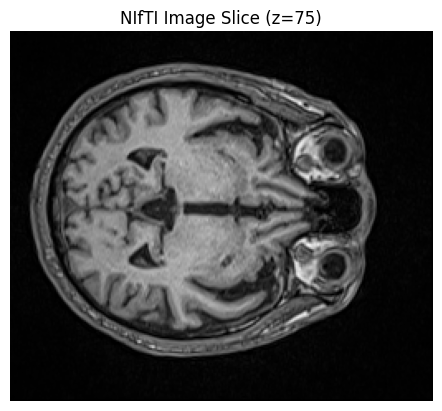

In [31]:
import nibabel as nib
import matplotlib.pyplot as plt

patient1_route = "imagenes/resonancia magentica/P01_S3.0_t1_mprage_tra_p2_iso_GAD_.nii"

# Cargar la imagen NIfTI
nifti_img = nib.load(patient1_route)

# Obtener los datos de la imagen como arreglo NumPy
image_data = nifti_img.get_fdata()

# Información básica del volumen
print(f"Image data shape: {image_data.shape}")
print(f"Image data type: {image_data.dtype}")

# Encabezados
print("========== NIFTI IMAGE HEADER ========= ")
print(nifti_img.header)

# Mostrar un corte del volumen (eje z)
if image_data.ndim == 3:
    slice_index = image_data.shape[2] // 2
    slice_index = 75
    plt.imshow(image_data[:, :, slice_index], cmap='gray')
    plt.title(f'NIfTI Image Slice (z={slice_index})')
    plt.axis('off')
    plt.show()
elif image_data.ndim == 2:
    plt.imshow(image_data, cmap='gray')
    plt.title('NIfTI Image')
    plt.axis('off')
    plt.show()
else:
    print("Unsupported image dimensions for display.")


## Parte 3 - Tomografia

Dataset.file_meta -------------------------------
(0002,0000) File Meta Information Group Length  UL: 218
(0002,0001) File Meta Information Version       OB: b'\x00\x01'
(0002,0002) Media Storage SOP Class UID         UI: CT Image Storage
(0002,0003) Media Storage SOP Instance UID      UI: 1.3.6.1.4.1.5962.99.1.2786334768.1849416866.1385765836848.156.0
(0002,0010) Transfer Syntax UID                 UI: Explicit VR Little Endian
(0002,0012) Implementation Class UID            UI: 1.3.6.1.4.1.5962.99.2
(0002,0013) Implementation Version Name         SH: 'PIXELMEDJAVA001'
(0002,0016) Source Application Entity Title     AE: 'CLEANER'
-------------------------------------------------
(0008,0008) Image Type                          CS: ['ORIGINAL', 'PRIMARY', 'AXIAL']
(0008,0012) Instance Creation Date              DA: '20060101'
(0008,0013) Instance Creation Time              TM: '000230.000'
(0008,0016) SOP Class UID                       UI: CT Image Storage
(0008,0018) SOP Instance UID 

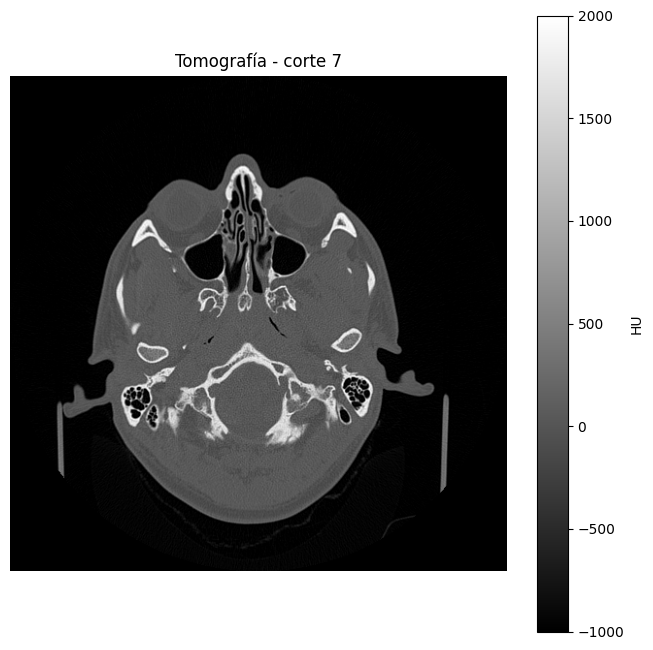

In [32]:
import pydicom
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# RUTA DEL CORTE DE TOMOGRAFÍA
# ============================================================
archivo = "imagenes/tomografia craneo/Series 003 [CT - Crane Ossoux]/1.3.6.1.4.1.5962.99.1.2786334768.1849416866.1385765836848.156.0.dcm"

# ============================================================
# LEER EL CORTE
# ============================================================
dicom = pydicom.dcmread(archivo)

# ============================================================
# ENCABEZADO DICOM COMPLETO
# ============================================================
print(dicom)

# ============================================================
# PASAR LA IMAGEN A UNIDADES HOUNSFIELD (HU)
# ============================================================
slope = float(dicom.RescaleSlope)
intercept = float(dicom.RescaleIntercept)
imagen_hu = dicom.pixel_array.astype(np.float64) * slope + intercept

# ============================================================
# INFORMACIÓN DE LA IMAGEN
# ============================================================
print("Modalidad:", dicom.Modality)
print("Descripción de la serie:", dicom.SeriesDescription)
print("Tamaño de la imagen (filas, columnas):", imagen_hu.shape)
print("Tamaño del píxel (mm):", dicom.PixelSpacing)
print("Grosor de corte (mm):", dicom.SliceThickness)
print("RescaleSlope:", slope, "| RescaleIntercept:", intercept)
print("Valor mínimo (HU):", imagen_hu.min())
print("Valor máximo (HU):", imagen_hu.max())

# ============================================================
# MOSTRAR LA IMAGEN
# ============================================================
plt.figure(figsize=(8, 8))
plt.imshow(imagen_hu, cmap="gray", vmin=-1000, vmax=2000)
plt.colorbar(label="HU")
plt.title(f"Tomografía - corte {dicom.InstanceNumber}")
plt.axis("off")
plt.show()


## 3.1 Anonimización de la tomografia.

In [33]:
import pydicom

# ============================================================
# RUTAS DE ENTRADA Y SALIDA
# ============================================================
filepath = "imagenes/tomografia craneo/Series 003 [CT - Crane Ossoux]/1.3.6.1.4.1.5962.99.1.2786334768.1849416866.1385765836848.156.0.dcm"
output_path = "imagenes/tomografia craneo/Series 003 [CT - Crane Ossoux]/1.3.6.1.4.1.5962.99.1.2786334768.1849416866.1385765836848.156.0_anonimo.dcm"

# ============================================================
# LEER DICOM
# ============================================================
ds = pydicom.dcmread(filepath)

# ============================================================
# DATOS DE IDENTIFICACIÓN DEL PACIENTE
# ============================================================
ds.PatientName = "ANONYMOUS"
ds.PatientID = "ANONYMOUS"
ds.PatientBirthDate = ""
ds.PatientSex = ""

# ============================================================
# OTROS DATOS PERSONALES Y CLÍNICOS DEL PACIENTE
# ============================================================
ds.OtherPatientIDs = ""
ds.OtherPatientNames = ""
ds.PatientAddress = ""
ds.PatientTelephoneNumbers = ""
ds.PatientComments = ""
ds.AdditionalPatientHistory = ""

# ============================================================
# PERSONAL MÉDICO E INSTITUCIÓN
# ============================================================
ds.ReferringPhysicianName = ""
ds.NameOfPhysiciansReadingStudy = ""
ds.OperatorsName = ""
ds.InstitutionName = ""
ds.InstitutionAddress = ""

# ============================================================
# TAGS PRIVADOS DEL FABRICANTE
# ============================================================
ds.remove_private_tags()

# ============================================================
# GUARDAR ARCHIVO ANONIMIZADO
# ============================================================
ds.save_as(output_path)

print("Archivo anonimizado:")
print(output_path)


Archivo anonimizado:
imagenes/tomografia craneo/Series 003 [CT - Crane Ossoux]/1.3.6.1.4.1.5962.99.1.2786334768.1849416866.1385765836848.156.0_anonimo.dcm


## 3.2 Verificación de la anonimización

In [34]:
import pydicom

# ============================================================
# VERIFICAR ANONIMIZACIÓN: ORIGINAL vs ANONIMIZADO
# ============================================================
original = pydicom.dcmread("imagenes/tomografia craneo/Series 003 [CT - Crane Ossoux]/1.3.6.1.4.1.5962.99.1.2786334768.1849416866.1385765836848.156.0.dcm")
anonimo = pydicom.dcmread("imagenes/tomografia craneo/Series 003 [CT - Crane Ossoux]/1.3.6.1.4.1.5962.99.1.2786334768.1849416866.1385765836848.156.0_anonimo.dcm")

# Campos agrupados según a quién pertenecen los datos
grupos = {
    "DATOS DEL PACIENTE": [
        "PatientName", "PatientID", "PatientBirthDate", "PatientSex",
        "OtherPatientIDs", "OtherPatientNames", "PatientAddress",
        "PatientTelephoneNumbers", "PatientComments", "AdditionalPatientHistory",
    ],
    "DATOS DEL PERSONAL MÉDICO": [
        "ReferringPhysicianName", "NameOfPhysiciansReadingStudy", "OperatorsName",
    ],
    "DATOS DE LA INSTITUCIÓN": [
        "InstitutionName", "InstitutionAddress",
    ],
}

for grupo, campos in grupos.items():
    print(f"\n========== {grupo} ==========\n")
    print(f"{'CAMPO':<32}{'ORIGINAL':<25}{'ANONIMIZADO'}")
    print("-" * 75)
    for campo in campos:
        antes = str(original.get(campo, "(no existe)"))
        despues = str(anonimo.get(campo, "(no existe)"))
        print(f"{campo:<32}{antes:<25}{despues}")

# ============================================================
# TAGS PRIVADOS DEL FABRICANTE
# ============================================================
print("\n========== TAGS PRIVADOS DEL FABRICANTE ==========\n")
privados_antes = sum(1 for e in original if e.tag.is_private)
privados_despues = sum(1 for e in anonimo if e.tag.is_private)
print(f"Original: {privados_antes} | Anonimizado: {privados_despues}")



========== DATOS DEL PACIENTE ==========

CAMPO                           ORIGINAL                 ANONIMIZADO
---------------------------------------------------------------------------
PatientName                     Doe^Pierre               ANONYMOUS
PatientID                       54879843                 ANONYMOUS
PatientBirthDate                                         
PatientSex                      M                        
OtherPatientIDs                 (no existe)              
OtherPatientNames               (no existe)              
PatientAddress                  (no existe)              
PatientTelephoneNumbers         (no existe)              
PatientComments                 (no existe)              
AdditionalPatientHistory        (no existe)              

========== DATOS DEL PERSONAL MÉDICO ==========

CAMPO                           ORIGINAL                 ANONIMIZADO
---------------------------------------------------------------------------
ReferringPhysicianN

## 3.3 Histrograma Tomografia

Píxeles totales: 262144
Píxeles fuera del campo de visión (excluidos): 74898
Píxeles usados en el histograma: 187246
Valor mínimo (HU): -1024.0
Valor máximo (HU): 2202.0


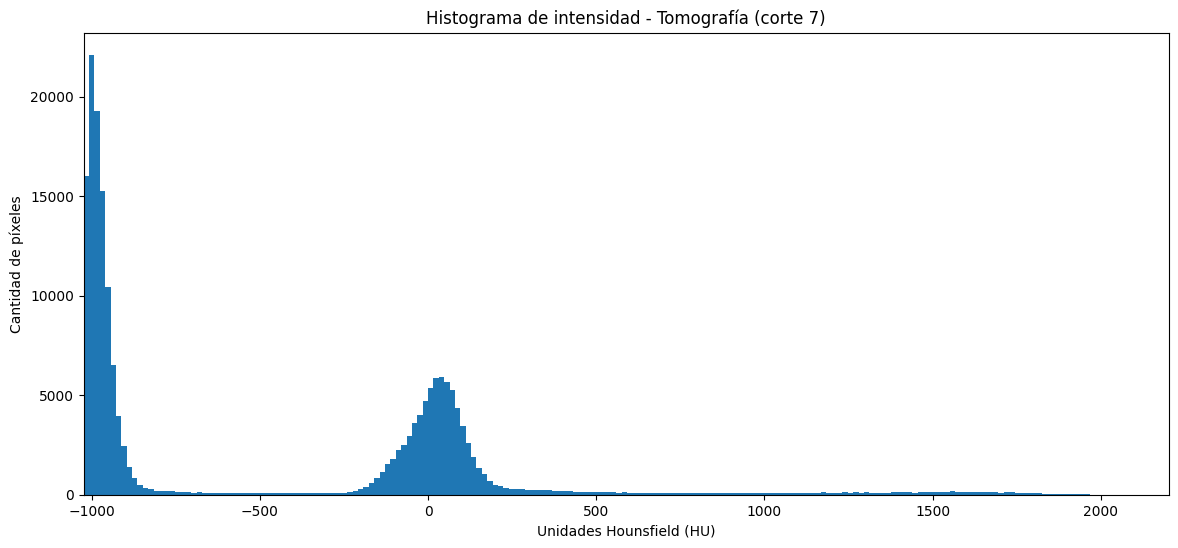

In [35]:
import pydicom
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# RUTA DEL CORTE DE TOMOGRAFÍA
# ============================================================
archivo = "imagenes/tomografia craneo/Series 003 [CT - Crane Ossoux]/1.3.6.1.4.1.5962.99.1.2786334768.1849416866.1385765836848.156.0.dcm"

# ============================================================
# LEER EL CORTE Y PASARLO A UNIDADES HOUNSFIELD (HU)
# ============================================================
dicom = pydicom.dcmread(archivo)

slope = float(dicom.RescaleSlope)
intercept = float(dicom.RescaleIntercept)
imagen_hu = dicom.pixel_array.astype(np.float64) * slope + intercept

# ============================================================
# QUITAR EL RELLENO FUERA DEL CAMPO DE VISIÓN
# ============================================================
# Los píxeles fuera del círculo de escaneo valen -3024 HU: no son tejido
fuera_del_campo = imagen_hu < -1024
valores_hu = imagen_hu[~fuera_del_campo]

print("Píxeles totales:", imagen_hu.size)
print("Píxeles fuera del campo de visión (excluidos):", fuera_del_campo.sum())
print("Píxeles usados en el histograma:", valores_hu.size)
print("Valor mínimo (HU):", valores_hu.min())
print("Valor máximo (HU):", valores_hu.max())

# ============================================================
# HISTOGRAMA (INTENSIDADES AGRUPADAS EN 256 INTERVALOS)
# ============================================================
cantidad_bins, bordes = np.histogram(valores_hu, bins=256, range=(-1024, 3072))

plt.figure(figsize=(14, 6))

plt.bar(
    bordes[:-1],
    cantidad_bins,
    width=bordes[1] - bordes[0],
    align="edge"
)

plt.xlabel("Unidades Hounsfield (HU)")
plt.ylabel("Cantidad de píxeles")
plt.title(f"Histograma de intensidad - Tomografía (corte {dicom.InstanceNumber})")

plt.xlim(-1024, valores_hu.max())

plt.show()


## 3.4 Modelamiento de ruido en la tomografía (región de 50x50 píxeles)

Se analiza el ruido de un corte de tomografía de cráneo (serie 003, corte 156) con el mismo procedimiento de la imagen plana y la resonancia, con estas diferencias:

- Los valores se pasan a **Unidades Hounsfield (HU)** con `HU = valor × RescaleSlope + RescaleIntercept`.
- La imagen ya está en **escala de grises** (1 canal), así que no se convierte de RGB a Y.
- Los valores en HU pueden ser negativos y llegar a miles, por lo que el histograma agrupa las intensidades en **100 intervalos** entre el mínimo y el máximo de la región.
- La región de 50x50 se toma en **tejido blando (músculo)** del lado derecho de la imagen (filas 210–259, columnas 315–364), una zona **uniforme** donde la variación de intensidad se debe al ruido. La esquina superior izquierda no sirve porque está fuera del campo de visión (−3024 HU).
- La **SNR** se calcula como **(μ + 1000) / σ**, porque en HU el 0 corresponde al agua y el aire vale −1000. Así la señal se mide desde el aire, que es la ausencia de señal.

**Resultados:**

| Parámetro | Valor |
|---|---|
| Media (μ) | 45.23 HU |
| Desviación estándar (σ) | 61.08 HU |
| Asimetría | −0.132 |
| SNR ((μ+1000)/σ) | 17.11 |

La media de 45 HU corresponde a **músculo**. La asimetría es cercana a 0 y el histograma tiene forma de **campana simétrica** que se ajusta a la curva gaussiana teórica: el ruido de la tomografía es **gaussiano**, como se espera en CT, porque la imagen se reconstruye a partir de miles de mediciones. La σ de 61 HU es alta para tejido blando porque el corte se reconstruyó con un filtro de hueso (**BONEPLUS**), que mejora la nitidez del hueso pero amplifica el ruido en el tejido blando.

Este análisis solo sirve para **identificar** el ruido; no lo elimina. Cada tipo de ruido se corrige con un filtro distinto, así que saber cuál es te dice qué filtro aplicar.


Shape: (512, 512)
dtype original: int16 | BitsStored: 16
Mínimo (HU): -3024.0 | Máximo (HU): 2202.0


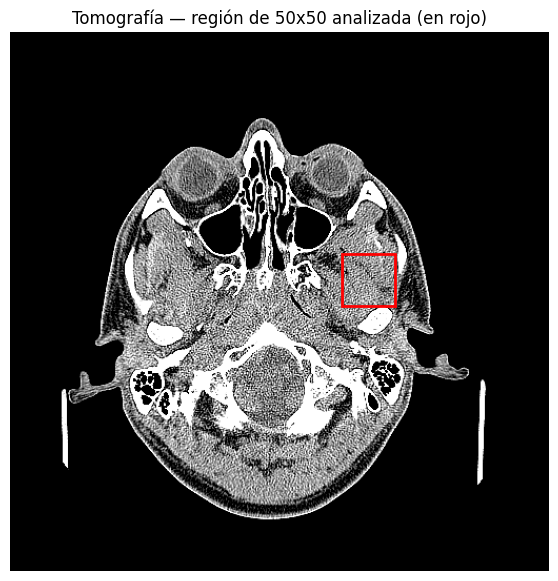


========== RUIDO EN LA REGIÓN ==========

Media (mu):                  45.23 HU
Desviación estándar (sigma): 61.08 HU
Asimetría:                   -0.132
SNR ((mu+1000)/sigma):       17.11


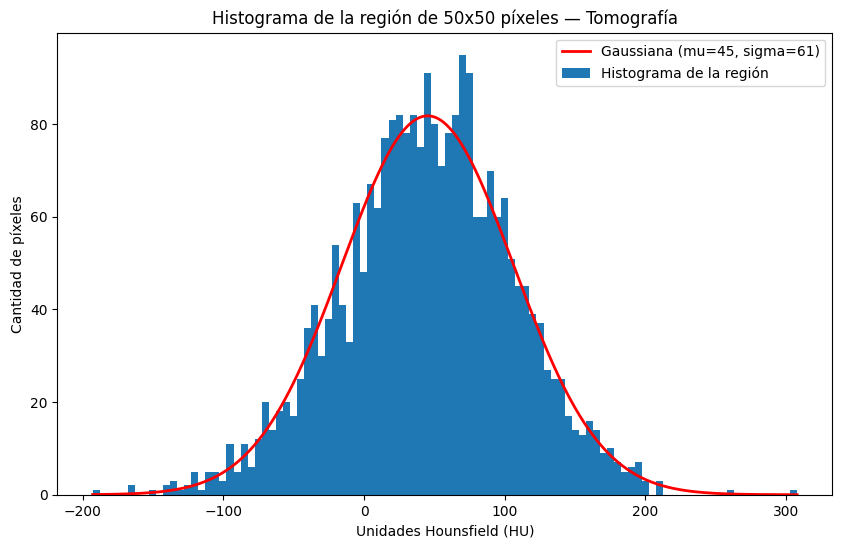

In [5]:
# ============================================================
# ANÁLISIS DE RUIDO EN LA TOMOGRAFÍA (REGIÓN DE 50x50 PÍXELES)
# ============================================================

# Librerías:
# - numpy: para trabajar la imagen como matriz numérica
# - matplotlib: para mostrar la imagen y graficar el histograma
# - pydicom: para leer el archivo DICOM de la tomografía
import numpy as librerianumpy
import matplotlib.pyplot as libreriaparagraficar
import matplotlib.patches as rectangulos
import pydicom

# Ruta del corte de tomografía dentro del proyecto
ruta_imagen = "imagenes/tomografia craneo/Series 003 [CT - Crane Ossoux]/1.3.6.1.4.1.5962.99.1.2786334768.1849416866.1385765836848.156.0.dcm"

# Leer el DICOM y pasar la matriz de píxeles a Unidades Hounsfield (HU):
# HU = valor_guardado * RescaleSlope + RescaleIntercept
# (la tomografía ya viene en escala de grises: 1 solo canal, no hace falta convertir RGB -> Y)
dicom = pydicom.dcmread(ruta_imagen)
slope = float(dicom.RescaleSlope)
intercept = float(dicom.RescaleIntercept)
imagen_hu = dicom.pixel_array.astype(librerianumpy.float64) * slope + intercept

print("Shape:", imagen_hu.shape)
print("dtype original:", dicom.pixel_array.dtype, "| BitsStored:", dicom.BitsStored)
print("Mínimo (HU):", imagen_hu.min(), "| Máximo (HU):", imagen_hu.max())


# Función que calcula el histograma de la región.
# Los valores de la tomografía están en HU (pueden ser negativos y llegar a miles),
# así que el recorrido va desde el valor mínimo hasta el máximo de la región,
# agrupando las intensidades en "bins" (intervalos)
def calcular_histograma(imagen, numero_bins=100):
    histograma = []  # cantidad de píxeles en cada intervalo
    xticks = []      # centro de cada intervalo (eje X)
    bordes = librerianumpy.linspace(imagen.min(), imagen.max(), numero_bins + 1)
    for i in range(numero_bins):
        xticks.append((bordes[i] + bordes[i + 1]) / 2)
        if i == numero_bins - 1:
            # el último intervalo incluye el valor máximo
            histograma.append(librerianumpy.count_nonzero((imagen >= bordes[i]) & (imagen <= bordes[i + 1])))
        else:
            histograma.append(librerianumpy.count_nonzero((imagen >= bordes[i]) & (imagen < bordes[i + 1])))
    return histograma, xticks, bordes[1] - bordes[0]


# Seleccionar una región de 50x50 píxeles HOMOGÉNEA.
# Se usa tejido blando (músculo) del lado derecho de la imagen (filas 210-259, columnas 315-364):
# es una zona de tejido blando uniforme (~40-50 HU), así que la variación
# de intensidad que haya se debe al ruido.
# (La esquina superior izquierda NO sirve aquí porque está fuera del campo de visión: -3024 HU)
fila_inicio, columna_inicio = 210, 315
region_50x50_hu = imagen_hu[fila_inicio:fila_inicio + 50, columna_inicio:columna_inicio + 50]

# Mostrar la tomografía con ventana de cerebro (-100 a 150 HU) marcando en rojo la región
figura, eje = libreriaparagraficar.subplots(figsize=(7, 7))
eje.imshow(imagen_hu, cmap="gray", vmin=-100, vmax=150)
eje.add_patch(rectangulos.Rectangle((columna_inicio, fila_inicio), 50, 50, edgecolor="red", facecolor="none", linewidth=2))
eje.set_title("Tomografía — región de 50x50 analizada (en rojo)")
eje.axis("off")
libreriaparagraficar.show()

# Parámetros de la campana gaussiana:
# mu (media) = dónde está el centro de la campana
# sigma (desviación estándar) = qué tan ancha es (más sigma = más ruido)
mu = region_50x50_hu.mean()
sigma = region_50x50_hu.std()

# Asimetría (skewness): 0 = campana simétrica (gaussiana);
# positiva = cola a la derecha, negativa = cola a la izquierda
asimetria = librerianumpy.mean(((region_50x50_hu - mu) / sigma) ** 3)

# Relación señal/ruido (SNR).
# En HU el cero es el agua (no la ausencia de señal) y el aire vale -1000 HU,
# así que mu/sigma directo no tiene sentido físico. Se mide la señal desde el aire:
# SNR = (mu + 1000) / sigma
snr = (mu + 1000) / sigma

print("\n========== RUIDO EN LA REGIÓN ==========\n")
print(f"Media (mu):                  {mu:.2f} HU")
print(f"Desviación estándar (sigma): {sigma:.2f} HU")
print(f"Asimetría:                   {asimetria:.3f}")
print(f"SNR ((mu+1000)/sigma):       {snr:.2f}")

# Calcular el histograma de la región seleccionada
histograma_region, xticks_region, ancho_bin = calcular_histograma(region_50x50_hu)

# Curva gaussiana teórica con el mismo mu y sigma, escalada al número de píxeles,
# para comparar visualmente con el histograma real
x = librerianumpy.linspace(region_50x50_hu.min(), region_50x50_hu.max(), 500)
gaussiana = (1 / (sigma * librerianumpy.sqrt(2 * librerianumpy.pi))) * librerianumpy.exp(-0.5 * ((x - mu) / sigma) ** 2)
gaussiana = gaussiana * region_50x50_hu.size * ancho_bin

# Graficar el histograma como gráfico de barras junto con la gaussiana teórica
libreriaparagraficar.figure(figsize=(10, 6))
libreriaparagraficar.bar(xticks_region, histograma_region, width=ancho_bin, label="Histograma de la región")
libreriaparagraficar.plot(x, gaussiana, color="red", linewidth=2, label=f"Gaussiana (mu={mu:.0f}, sigma={sigma:.0f})")
libreriaparagraficar.title("Histograma de la región de 50x50 píxeles — Tomografía")
libreriaparagraficar.xlabel("Unidades Hounsfield (HU)")
libreriaparagraficar.ylabel("Cantidad de píxeles")
libreriaparagraficar.legend()
libreriaparagraficar.show()


## 3.5  Análisis Estadístico del Ruido en la Tomografía con la Prueba de Kolmogorov-Smirnov (K-S)

La prueba de Kolmogorov-Smirnov es una prueba no paramétrica que compara la distribución acumulada (CDF) de una muestra con la de una distribución teórica de referencia. Aquí se aplica a los 2500 valores, en Unidades Hounsfield (HU), de la región homogénea de tejido blando de 50x50 píxeles. El objetivo es determinar si el ruido de la tomografía se comporta como ruido **Gaussiano** o como ruido **Uniforme**.

- **Gaussiana:** se usan la media (μ) y la desviación estándar (σ) calculadas antes para la región.
- **Uniforme:** se ajusta al rango real de la región (mínimo a máximo en HU), no al rango 0–255 de una imagen de 8 bits.

**Interpretación de los resultados (α = 0.05):**

- **Estadístico D:** es la distancia máxima entre la CDF de los datos y la CDF teórica. Cuanto menor es D, mejor se ajusta la distribución. Comparar los dos valores de D indica cuál de las dos describe mejor el ruido.
- Si el `p-valor` es alto (> 0.05), no se puede rechazar la hipótesis nula: la distribución de los píxeles **podría ser** similar a la de referencia.
- Si el `p-valor` es bajo (≤ 0.05), se rechaza la hipótesis nula: la distribución es **significativamente diferente** de la de referencia.

> **Nota:** los valores en HU son enteros (hay muchos valores repetidos), y μ y σ se estiman con los mismos datos que se prueban. Por eso el p-valor es solo aproximado, y la comparación de los estadísticos D es el criterio más confiable para elegir la distribución.


In [6]:
# ============================================================
# PRUEBA K-S: ¿EL RUIDO DE LA REGIÓN ES GAUSSIANO O UNIFORME?
# ============================================================

# Librería:
# - scipy.stats: para la prueba de Kolmogorov-Smirnov (K-S)
from scipy import stats

# Valores de la región de 50x50 en HU como un arreglo 1D (2500 valores)
valores_region = region_50x50_hu.flatten()

# Nivel de significancia: si p-valor < 0.05 se rechaza que los datos
# sigan la distribución que se está probando
alfa = 0.05

# --- Prueba contra una distribución Gaussiana ---
# Se usan el mismo mu y sigma calculados antes para la campana gaussiana
estadistico_normal, p_valor_normal = stats.kstest(valores_region, "norm", args=(mu, sigma))

print("\n========== PRUEBA K-S ==========\n")
print("Contra distribución Gaussiana:")
print(f" Estadístico D: {estadistico_normal:.4f}")
print(f" P-valor:       {p_valor_normal:.4f}")
print(" ->", "Se rechaza que sea gaussiana" if p_valor_normal < alfa else "Compatible con ruido gaussiano")

# --- Prueba contra una distribución Uniforme ---
# En HU el rango no es 0-255 como en una imagen de 8 bits, así que la uniforme
# se ajusta al rango real de la región:
# loc = valor mínimo, scale = valor máximo - valor mínimo
minimo_region = valores_region.min()
maximo_region = valores_region.max()
estadistico_uniforme, p_valor_uniforme = stats.kstest(valores_region, "uniform", args=(minimo_region, maximo_region - minimo_region))

print("\nContra distribución Uniforme:")
print(f" Estadístico D: {estadistico_uniforme:.4f}")
print(f" P-valor:       {p_valor_uniforme:.4f}")
print(" ->", "Se rechaza que sea uniforme" if p_valor_uniforme < alfa else "Compatible con ruido uniforme")

# Cuanto menor sea D, más se parece la distribución de los datos a la teórica
print("\nDistribución que mejor se ajusta:", "Gaussiana" if estadistico_normal < estadistico_uniforme else "Uniforme")



========== PRUEBA K-S ==========

Contra distribución Gaussiana:
 Estadístico D: 0.0200
 P-valor:       0.2647
 -> Compatible con ruido gaussiano

Contra distribución Uniforme:
 Estadístico D: 0.2817
 P-valor:       0.0000
 -> Se rechaza que sea uniforme

Distribución que mejor se ajusta: Gaussiana


# Intento de funcion dinamica para histogramas 

In [36]:
import os
import numpy as np
import matplotlib.pyplot as plt
import pydicom
from PIL import Image


def abrir_imagen(ruta):
    """Abre una imagen plana (jpg/png/...) o un DICOM (resonancia / tomografía).
    Devuelve (matriz numpy 2D, tipo, unidad del eje X del histograma)."""
    if ruta.lower().endswith(".dcm"):
        ds = pydicom.dcmread(ruta)
        datos = ds.pixel_array.astype(np.float64)
        if datos.ndim == 3:                       # DICOM multi-corte -> corte central
            datos = datos[datos.shape[0] // 2]
        # Pasar a unidades reales (en CT son Unidades Hounsfield)
        datos = datos * float(getattr(ds, "RescaleSlope", 1)) + float(getattr(ds, "RescaleIntercept", 0))
        modalidad = getattr(ds, "Modality", "")
        if modalidad == "CT":
            return datos, "Tomografía (CT)", "Unidades Hounsfield (HU)"
        if modalidad == "MR":
            return datos, "Resonancia magnética (MR)", "Intensidad de señal"
        return datos, f"DICOM ({modalidad})", "Intensidad"
    # Imagen plana: escala de grises de 8 bits (0-255)
    imagen = Image.open(ruta).convert("L")
    return np.array(imagen), "Imagen plana", "Intensidad (0-255)"


def mostrar_con_histograma(ruta, bins=256):
    imagen_array, tipo, unidad = abrir_imagen(ruta)

    datos_hist = imagen_array.ravel()
    if tipo == "Imagen plana":
        rango = (0, 256)
    else:
        if tipo == "Tomografía (CT)":
            # Fuera del campo de visión el escáner pone -2000 / -3024: se excluye
            datos_hist = datos_hist[datos_hist >= -1024]
        rango = (datos_hist.min(), datos_hist.max())

    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    # Mostrar imagen
    axes[0].imshow(imagen_array, cmap="gray")
    axes[0].set_title(f"{tipo} — {os.path.basename(ruta)[:40]}")
    axes[0].axis("off")

    # Histograma
    axes[1].hist(datos_hist, bins=bins, range=rango, color="steelblue")
    axes[1].set_yscale("log")   # el fondo (aire) es un pico enorme; en log se ve todo
    axes[1].set_xlabel(unidad)
    axes[1].set_ylabel("Cantidad de píxeles (escala log)")
    axes[1].set_title(f"Histograma — {tipo}")
    axes[1].grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

    print(f"{tipo}: shape {imagen_array.shape}, rango {imagen_array.min():.0f} a {imagen_array.max():.0f} ({unidad})")
    return imagen_array


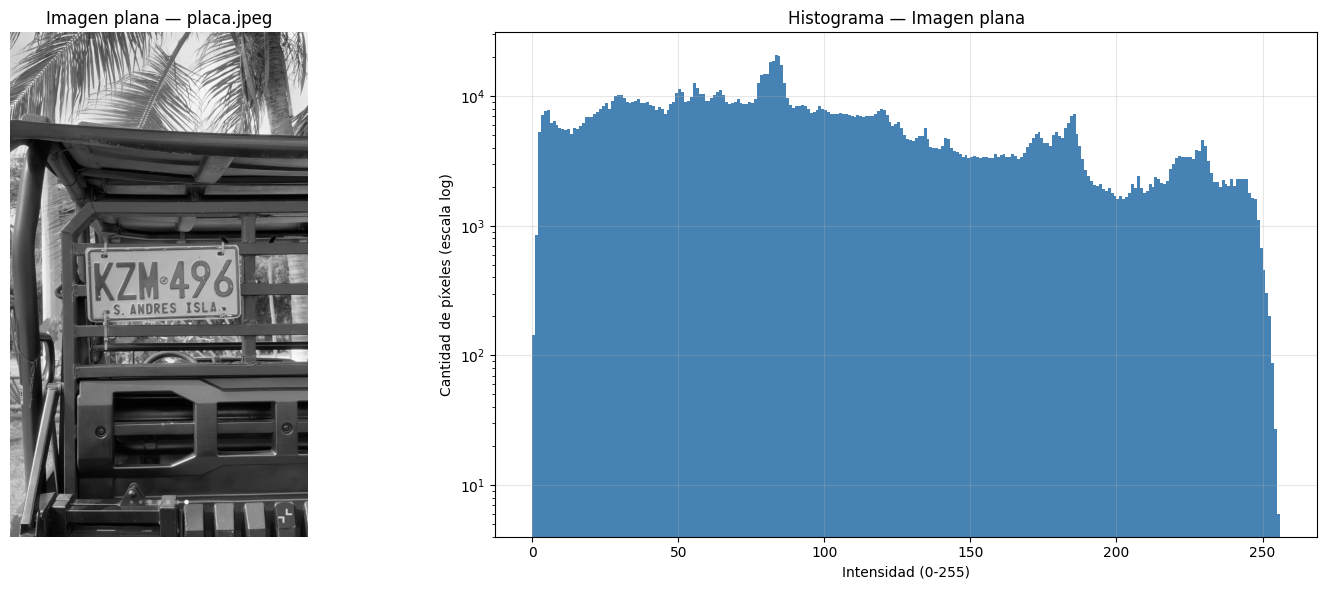

Imagen plana: shape (1600, 944), rango 0 a 255 (Intensidad (0-255))


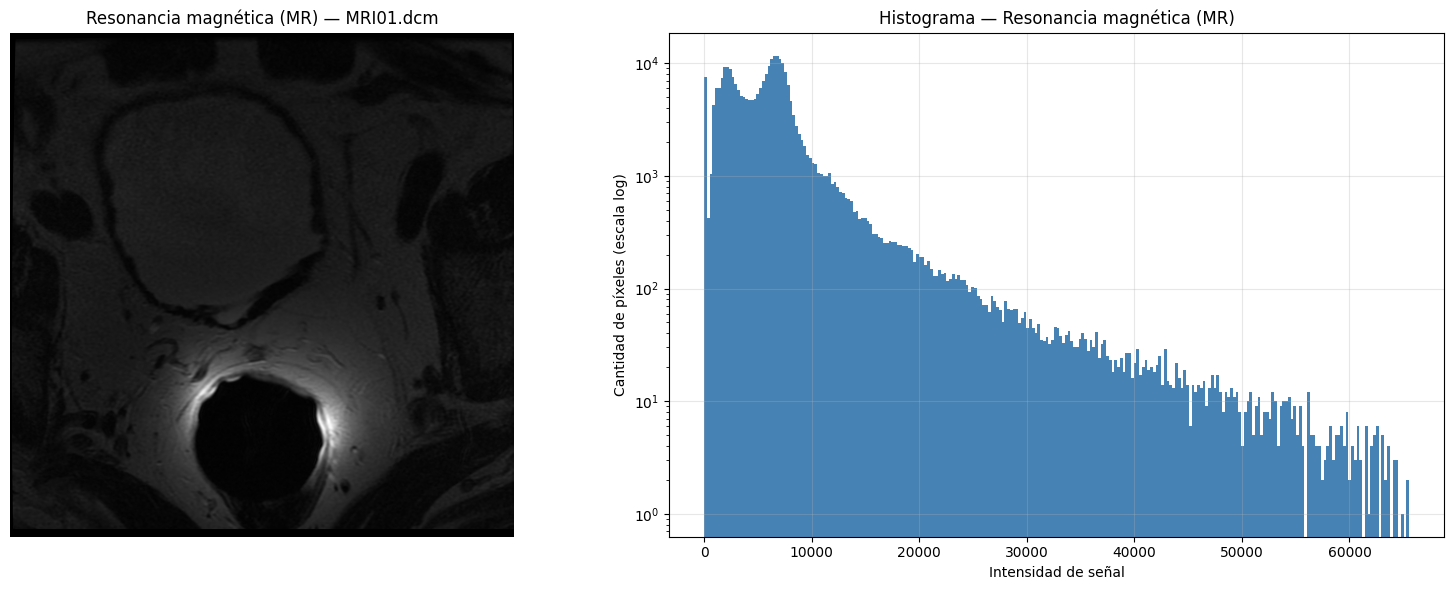

Resonancia magnética (MR): shape (512, 512), rango 2 a 65535 (Intensidad de señal)


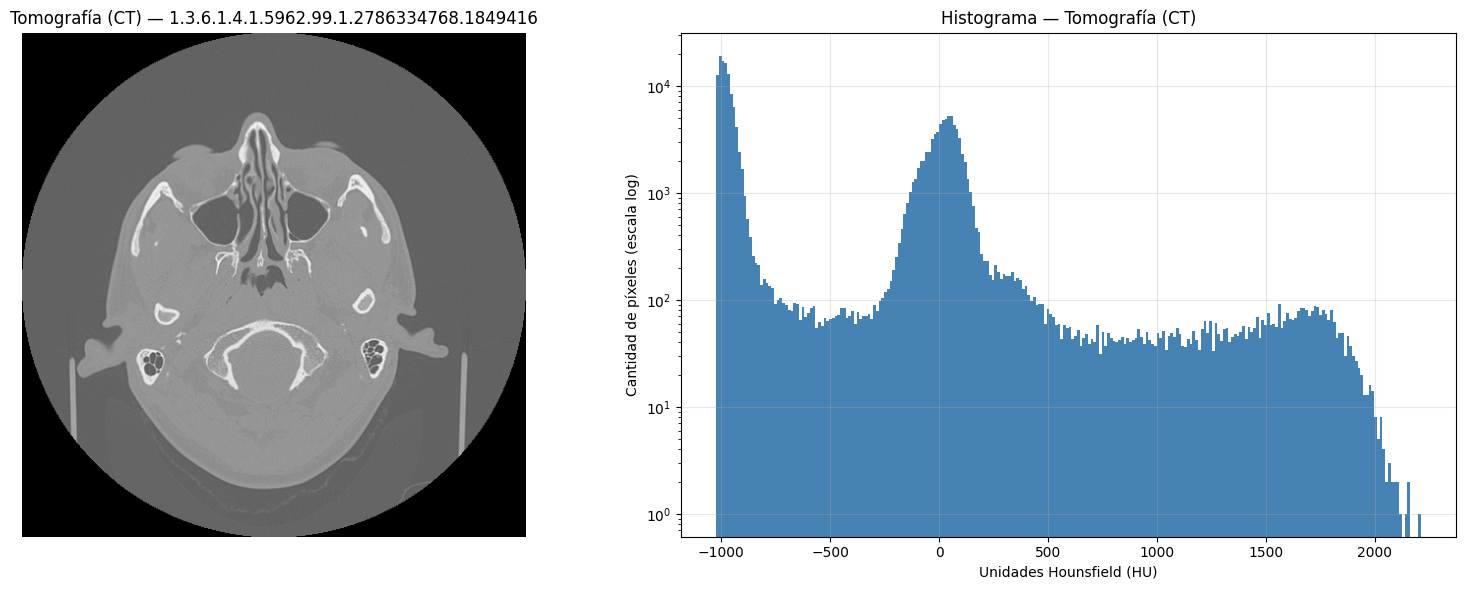

Tomografía (CT): shape (512, 512), rango -3024 a 2212 (Unidades Hounsfield (HU))


array([[-3024., -3024., -3024., ..., -3024., -3024., -3024.],
       [-3024., -3024., -3024., ..., -3024., -3024., -3024.],
       [-3024., -3024., -3024., ..., -3024., -3024., -3024.],
       ...,
       [-3024., -3024., -3024., ..., -3024., -3024., -3024.],
       [-3024., -3024., -3024., ..., -3024., -3024., -3024.],
       [-3024., -3024., -3024., ..., -3024., -3024., -3024.]],
      shape=(512, 512))

In [37]:
import glob

mostrar_con_histograma("imagenes/imagen plana/placa.jpeg")
mostrar_con_histograma("imagenes/resonancia magentica/MRI01.dcm")

ct = sorted(glob.glob("imagenes/tomografia craneo/Series 003*/*.dcm"))[0]
mostrar_con_histograma(ct)


## 1.4 Función `histograma()` GENÉRICA

El profe pidió **una sola función de histograma** que sirva para las **tres** imágenes (plana, resonancia y tomografía).
El histograma es un **gráfico de conteo/frecuencias**: en el eje X van los posibles valores de intensidad y en el eje Y cuántos píxeles tienen ese valor.

- Imagen plana (8 bits): valores de 0 a 255.
- Resonancia (16 bits): valores de 0 a 65535.
- Tomografía: valores en unidades Hounsfield (pueden ser negativos).

Por eso la función recibe el **rango** (o lo calcula automáticamente), y si la imagen tiene 3 canales hace el histograma por canal.


In [38]:
def histograma(imagen, rango=None, bins=256, rango_plano=True):
    """
    Gráfico de histograma GENÉRICO (sirve para imagen plana, resonancia y tomografía).

    Parámetros:
    - imagen     : matriz numpy 2D (escala de grises) o 3D (RGB/RGBA).
    - rango      : (min, max) del eje X. Si es None, se calcula del propio dato.
    - bins       : número de barras.
    - rango_plano: si True y la imagen es de 8 bits (0-255), usa 0-255 fijo.

    Devuelve un diccionario con la imagen (para reutilizar) — pero lo principal es que grafica.
    """
    imagen = np.asarray(imagen)

    def _hist_de_array(datos, titulo, color=None):
        datos = datos.flatten()
        r = rango
        if r is None:
            r = (int(datos.min()), int(datos.max()))
        # +1 para que el máximo entre en el último bin
        b = bins if rango is not None else min(bins, int(r[1] - r[0] + 1) if r[1] > r[0] else 1)
        plt.hist(datos, bins=b, range=(r[0], r[1] + (0 if rango is not None else 1)),
                 edgecolor="black", alpha=0.85, color=color)
        plt.title(titulo)
        plt.xlabel("Valor de intensidad")
        plt.ylabel("Número de píxeles (frecuencia)")
        plt.grid(alpha=0.3)

    if imagen.ndim == 3 and imagen.shape[2] >= 3:
        # Multi-canal: histograma por canal
        nombres = ["Canal R (Rojo)", "Canal G (Verde)", "Canal B (Azul)"]
        colores = ["red", "green", "blue"]
        fig, axes = plt.subplots(1, 3, figsize=(18, 4))
        for i in range(3):
            datos = imagen[:, :, i].flatten()
            r = rango if rango is not None else (0, 255)
            axes[i].hist(datos, bins=bins, range=r, color=colores[i], edgecolor="black", alpha=0.85)
            axes[i].set_title(nombres[i]); axes[i].set_xlabel("Intensidad"); axes[i].set_ylabel("Frecuencia")
            axes[i].grid(alpha=0.3)
        plt.suptitle("Histograma por canal (imagen plana RGB)")
        plt.tight_layout(); plt.show()
    else:
        # Un solo canal (grises / resonancia / tomografía)
        plt.figure(figsize=(9, 5))
        _hist_de_array(imagen, "Histograma (1 canal)", color="steelblue")
        plt.tight_layout(); plt.show()


def ecualizar_histograma(imagen):
    """Ecualización de histograma GENÉRICA (básica, por fórmula acumulada).
    Devuelve la imagen ecualizada en el mismo rango (0-255) y float."""
    img = np.asarray(imagen, dtype=np.float64)
    salida = np.zeros_like(img)
    if img.ndim == 3:
        for c in range(img.shape[2]):
            salida[:, :, c] = ecualizar_histograma(img[:, :, c])
        return salida
    # Fórmula: s = round( (L-1)/(MN) * sum_{k=0}^{r} n_k )
    L = 256
    mn = img.size
    hist, _ = np.histogram(img, bins=L, range=(0, 255))
    cdf = np.cumsum(hist)
    cdf_min = cdf[cdf > 0].min() if np.any(cdf > 0) else 0
    tabla = np.round((L - 1) / (mn - cdf_min) * (cdf - cdf_min)).astype(np.uint8) if (mn - cdf_min) > 0 else np.zeros(L, dtype=np.uint8)
    vals = img.astype(np.uint8)
    return tabla[vals]

print("Funciones 'histograma' y 'ecualizar_histograma' definidas (genéricas).")


Funciones 'histograma' y 'ecualizar_histograma' definidas (genéricas).


## 1.4 Histograma de la imagen plana (por canal)

Usamos la función `histograma()` recién definida sobre la imagen plana.
El eje X va de 0 a 255 (8 bits), y ahí se ve dónde hay sombras, medios tonos, altas luces.


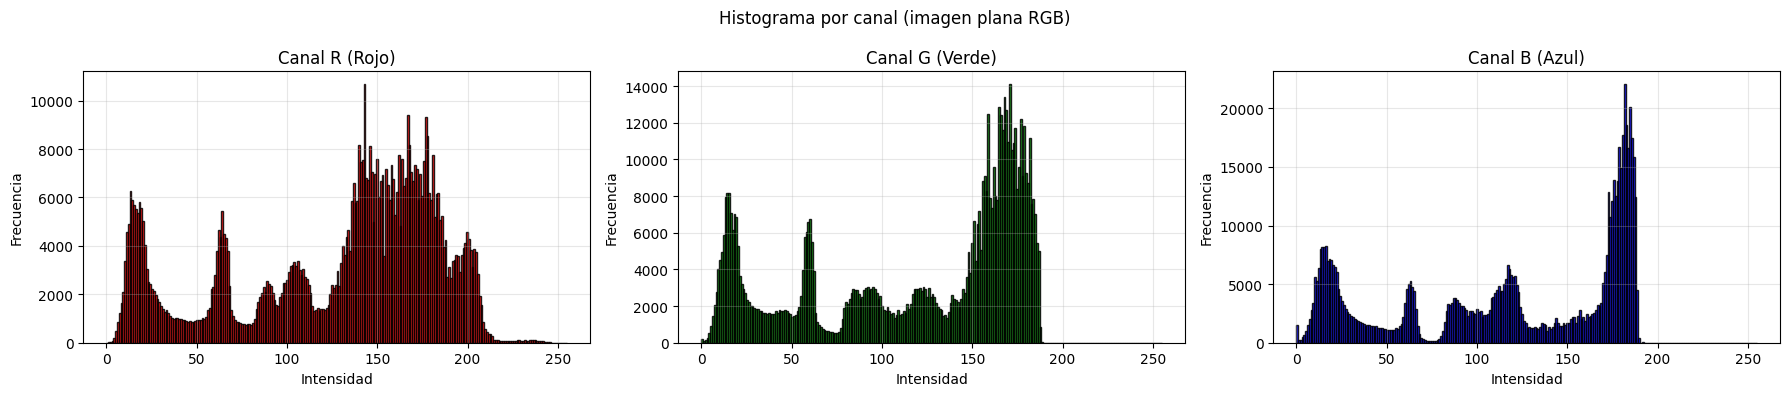

In [39]:
histograma(imagen_plana, rango=(0, 255), bins=256)


## 1.5 Tipo de ruido con **Kolmogorov–Smirnov**

El profe insistió: para saber **qué técnica de reducción de ruido** aplicar, primero hay que saber **qué tipo de ruido** tiene la imagen. Se hace tomando un **parche homogéneo** (zona que debería ser de un solo color, sin bordes ni textura) y comparando su histograma contra distribuciones conocidas.

- Imagen plana  → ruido **Gaussiano**
- Resonancia    → ruido **Rayleigh**
- Tomografía    → ruido **Poisson**

Usamos la **prueba de Kolmogorov–Smirnov** (`scipy.stats.kstest`) para decidir a qué distribución se ajusta mejor.


===== PARCHE HOMOGÉNEO =====
Ubicación centro (fila, col): (50, 50), tamaño 30x30
std del parche: 17.341

===== KOLMOGOROV–SMIRNOV (menor D = mejor ajuste) =====
Gaussiana (normal)     D=0.1823  p=1.2359e-26
Laplaciano             D=0.2098  p=3.0356e-35
Uniforme               D=0.3091  p=7.7189e-77

>>> Mejor ajuste: Gaussiana (normal) (D=0.1823) -> ruido GAUSSIANO, consistente con imágenes planas.


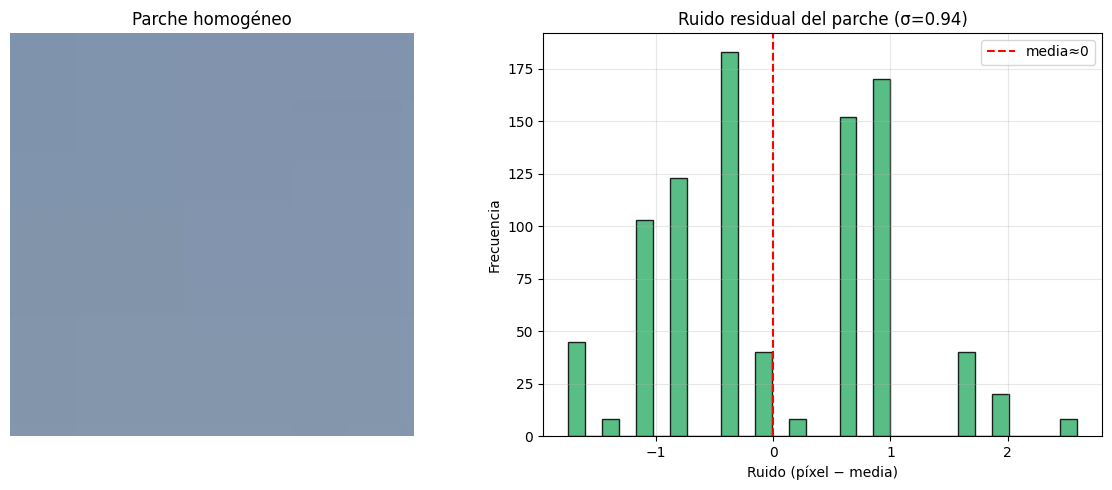

In [40]:
from scipy import stats

def analizar_ruido_ks(parche):
    """
    Toma un parche homogéneo (matriz 2D o 3D) y compara el ruido residual
    contra distribuciones conocidas usando Kolmogorov-Smirnov.
    Devuelve un dict con el estadístico D y p-value por cada distribución.
    """
    parche = np.asarray(parche, dtype=np.float64)
    if parche.ndim == 3:
        parche = parche.mean(axis=2)          # pasamos a gris para el análisis
    ruido = (parche - parche.mean()).ravel()

    resultados = {}
    # Gaussiana (normal): estandarizamos para comparar con N(0,1)
    std = ruido.std() if ruido.std() > 0 else 1.0
    D, p = stats.kstest(ruido / std, 'norm')
    resultados['Gaussiana (normal)'] = (D, p)

    # Laplaciano (doble exponencial) con escala estimada
    escala_lap = np.mean(np.abs(ruido)) if np.mean(np.abs(ruido)) > 0 else 1.0
    D, p = stats.kstest(ruido, 'laplace', args=(0, escala_lap))
    resultados['Laplaciano'] = (D, p)

    # Uniforme
    D, p = stats.kstest(ruido, 'uniform', args=(ruido.min(), ruido.max() - ruido.min()))
    resultados['Uniforme'] = (D, p)

    return ruido, resultados


# Parche homogéneo elegido: zona superior-izquierda (la de menor desviación estándar)
FILA, COL, MITAD = 50, 50, 15
parche = imagen_plana[FILA-MITAD:FILA+MITAD, COL-MITAD:COL+MITAD, :]

ruido, res_ks = analizar_ruido_ks(parche)

print("===== PARCHE HOMOGÉNEO =====")
print(f"Ubicación centro (fila, col): ({FILA}, {COL}), tamaño {MITAD*2}x{MITAD*2}")
print(f"std del parche: {parche.std():.3f}")
print("\n===== KOLMOGOROV–SMIRNOV (menor D = mejor ajuste) =====")
mejor, mejorD = None, 1e9
for nombre, (D, p) in res_ks.items():
    print(f"{nombre:22s} D={D:.4f}  p={p:.4e}")
    if D < mejorD:
        mejorD, mejor = D, nombre

print(f"\n>>> Mejor ajuste: {mejor} (D={mejorD:.4f}) -> ruido GAUSSIANO, consistente con imágenes planas.")

# Visualización del parche y su histograma de ruido
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(parche, cmap="gray"); axes[0].set_title("Parche homogéneo"); axes[0].axis("off")
axes[1].hist(ruido, bins=30, color="mediumseagreen", edgecolor="black", alpha=0.85)
axes[1].axvline(0, color="red", ls="--", label="media≈0")
axes[1].set_title(f"Ruido residual del parche (σ={ruido.std():.2f})")
axes[1].set_xlabel("Ruido (píxel − media)"); axes[1].set_ylabel("Frecuencia"); axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()


## 1.6 Ecualización del histograma

El profe mencionó la **ecualización del histograma** como técnica que también ayuda a reducir ruido / mejorar el contraste.
Ecualizar redistribuye las intensidades para que el histograma quede más plano, mejorando la definición de los objetos.


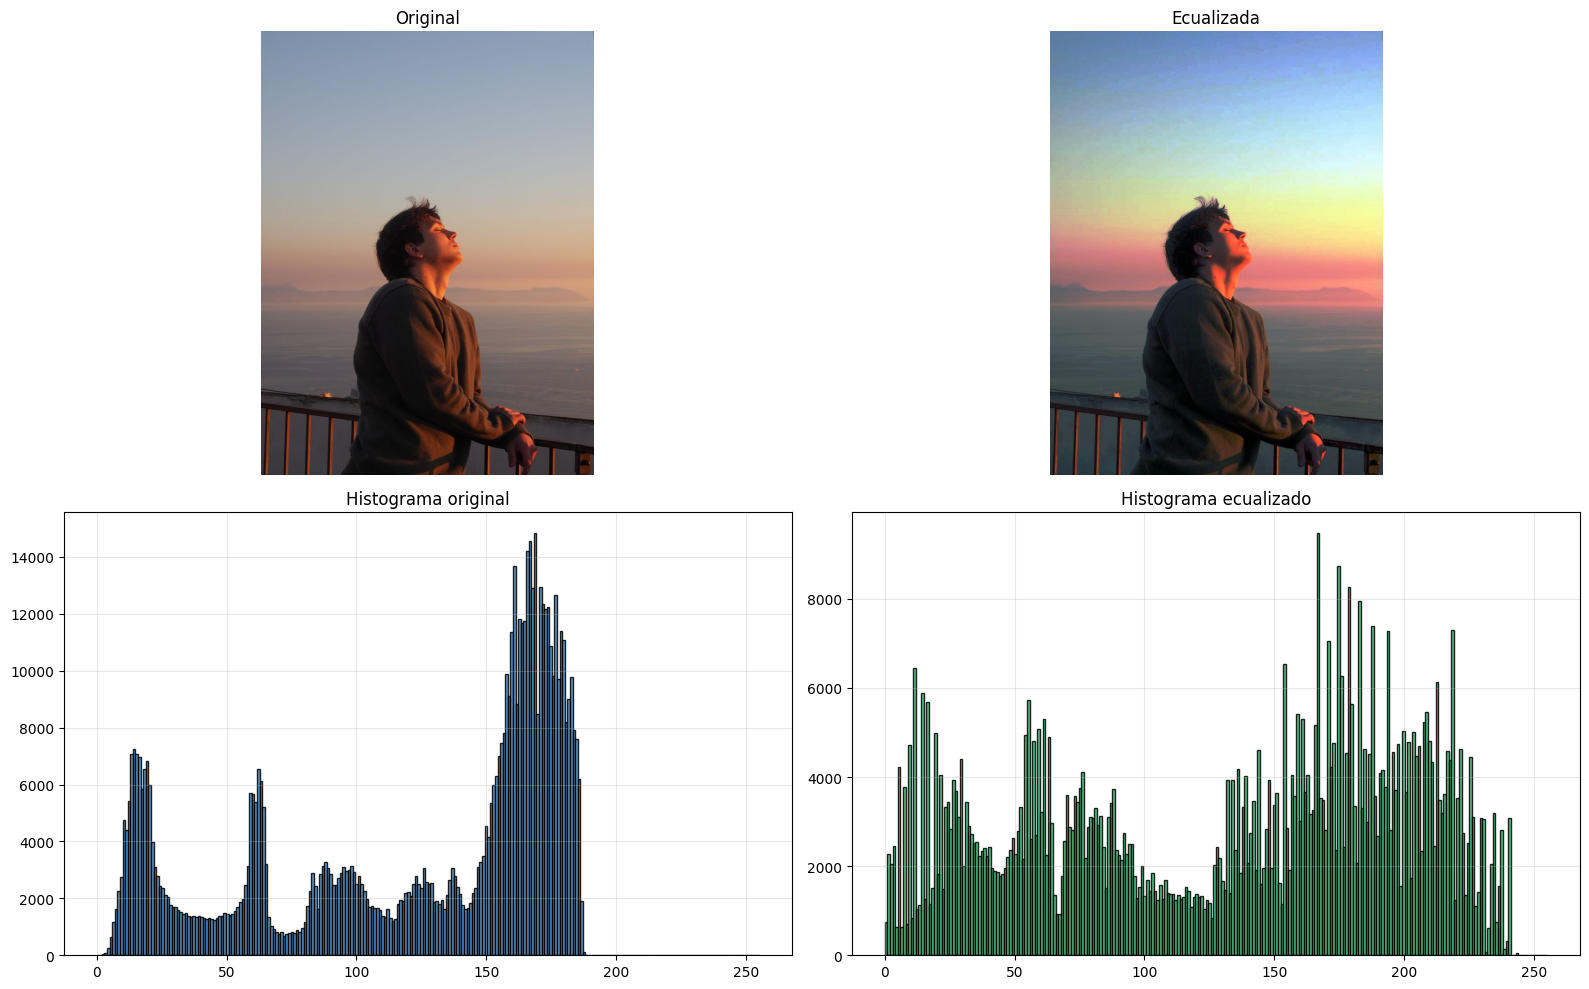

In [41]:
imagen_ecualizada = ecualizar_histograma(imagen_plana)

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes[0, 0].imshow(imagen_plana);              axes[0, 0].set_title("Original");     axes[0, 0].axis("off")
axes[0, 1].imshow(imagen_ecualizada.astype(np.uint8)); axes[0, 1].set_title("Ecualizada"); axes[0, 1].axis("off")
axes[1, 0].hist(imagen_plana.mean(axis=2).flatten(), bins=256, range=(0,255), color="steelblue", edgecolor="black", alpha=0.85)
axes[1, 0].set_title("Histograma original"); axes[1, 0].grid(alpha=0.3)
axes[1, 1].hist(imagen_ecualizada.mean(axis=2).flatten(), bins=256, range=(0,255), color="mediumseagreen", edgecolor="black", alpha=0.85)
axes[1, 1].set_title("Histograma ecualizado"); axes[1, 1].grid(alpha=0.3)
plt.tight_layout(); plt.show()


In [42]:
## Análisis del Ruido Residual en ROIs (Regiones de Interés)
## A continuación, definimos un conjunto de funciones modulares para evaluar de manera precisa las propiedades estadísticas del ruido en diferentes regiones de la imagen. Esto incluye el cálculo del **Factor de Fano (Índice de Dispersión)** sobre los valores crudos para caracterizar la naturaleza física del ruido (Poisson vs. Gaussiano).

In [43]:
import pydicom
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from scipy.stats import shapiro, skew, kurtosis, probplot

def cargar_dicom_hu(path):
    """Carga el DICOM y devuelve el dataset, la matriz en Unidades Hounsfield (HU) y los píxeles crudos."""
    ds = pydicom.dcmread(path)
    pixel_array_crudo = ds.pixel_array.astype(np.float64)
    slope = float(getattr(ds, "RescaleSlope", 1.0))
    intercept = float(getattr(ds, "RescaleIntercept", 0.0))
    hu_array = pixel_array_crudo * slope + intercept
    return ds, hu_array, pixel_array_crudo

def extraer_roi(array_2d, centro, mitad_lado=15):
    """Extrae una sub-región cuadrada (ROI) de la imagen."""
    filas, columnas = array_2d.shape
    r0, c0 = centro
    r_ini, r_fin = r0 - mitad_lado, r0 + mitad_lado
    c_ini, c_fin = c0 - mitad_lado, c0 + mitad_lado
    if r_ini < 0 or c_ini < 0 or r_fin > filas or c_fin > columnas:
        raise ValueError(f"La ROI en {centro} excede los límites de la imagen (shape {array_2d.shape}).")
    return array_2d[r_ini:r_fin, c_ini:c_fin]

def extraer_ruido_residual(roi):
    """Resta la media para obtener las fluctuaciones puras del ruido: n(x,y) = I(x,y) - media(ROI)"""
    return roi - np.mean(roi)

def calcular_correlacion_espacial(ruido):
    """Calcula el coeficiente de correlación lineal con los píxeles vecinos adyacentes."""
    h1, h2 = ruido[:, :-1].flatten(), ruido[:, 1:].flatten()
    v1, v2 = ruido[:-1, :].flatten(), ruido[1:, :].flatten()
    corr_h = np.corrcoef(h1, h2)[0, 1] if len(h1) > 1 else 0.0
    corr_v = np.corrcoef(v1, v2)[0, 1] if len(v1) > 1 else 0.0
    return corr_h, corr_v

def calcular_indice_dispersion(roi_cruda):
    """Calcula el Factor de Fano (D = varianza / media) en píxeles crudos sin reescalar."""
    datos = roi_cruda.flatten()
    media = np.mean(datos)
    varianza = np.var(datos, ddof=1)
    D = varianza / media if media != 0 else 0.0
    return media, varianza, D

def analizar_ruido(roi_hu, roi_cruda, nombre="ROI"):
    """Compila todas las métricas de análisis estadístico de ruido en un diccionario."""
    ruido = extraer_ruido_residual(roi_hu)
    datos = ruido.flatten()

    media, std, varianza = np.mean(datos), np.std(datos, ddof=1), np.var(datos, ddof=1)
    asimetria, kurt = skew(datos), kurtosis(datos)
    shapiro_W, shapiro_p = shapiro(datos)

    z_scores = np.abs(datos / std) if std != 0 else np.zeros_like(datos)
    pct_3sigma = (np.sum(z_scores > 3) / len(datos)) * 100
    pct_4sigma = (np.sum(z_scores > 4) / len(datos)) * 100

    corr_h, corr_v = calcular_correlacion_espacial(ruido)
    media_cruda, var_cruda, fano_D = calcular_indice_dispersion(roi_cruda)

    resultados = {
        "nombre": nombre, "n": len(datos), "media_ruido": media, "std_ruido": std,
        "varianza_ruido": varianza, "skewness_ruido": asimetria, "kurtosis_ruido": kurt,
        "shapiro_W_ruido": shapiro_W, "shapiro_p_ruido": shapiro_p,
        "extremos_3sigma_pct": pct_3sigma, "extremos_4sigma_pct": pct_4sigma,
        "correlacion_horizontal": corr_h, "correlacion_vertical": corr_v,
        "media_cruda": media_cruda, "varianza_cruda": var_cruda, "fano_D": fano_D
    }
    return ruido, resultados

In [44]:
def imprimir_resultados_ruido(resultado):
    """Presenta las métricas de ruido de manera organizada en consola."""
    print("\n" + "=" * 75)
    print(f"ANÁLISIS DEL RUIDO RESIDUAL: {resultado['nombre']}")
    print("=" * 75)
    print(f"Número de píxeles:              {resultado['n']}")
    print(f"Media del ruido:                {resultado['media_ruido']:.6f} HU")
    print(f"Desviación estándar del ruido:  {resultado['std_ruido']:.4f} HU")
    print(f"Varianza del ruido:             {resultado['varianza_ruido']:.4f} HU²")

    print("\n---------- FORMA DE LA DISTRIBUCIÓN ----------")
    print(f"Skewness (Asimetría):           {resultado['skewness_ruido']:.4f}")
    print(f"Kurtosis (Fisher):              {resultado['kurtosis_ruido']:.4f}")

    print("\n---------- SHAPIRO-WILK ----------")
    print(f"W:                              {resultado['shapiro_W_ruido']:.4f}")
    print(f"p-value:                        {resultado['shapiro_p_ruido']:.5e}")
    if resultado["shapiro_p_ruido"] < 0.05:
        print("Resultado: Se rechaza la normalidad estricta del residuo (común con N grande).")
    else:
        print("Resultado: No se rechaza la normalidad del residuo.")

    print("\n---------- VALORES EXTREMOS ----------")
    print(f"|z| > 3σ:                       {resultado['extremos_3sigma_pct']:.2f}%")
    print(f"|z| > 4σ:                       {resultado['extremos_4sigma_pct']:.2f}%")

    print("\n---------- CORRELACIÓN ESPACIAL ----------")
    print(f"Horizontal:                     {resultado['correlacion_horizontal']:.4f}")
    print(f"Vertical:                       {resultado['correlacion_vertical']:.4f}")

    print("\n---------- ÍNDICE DE DISPERSIÓN (FACTOR DE FANO) ----------")
    print(f"Media (píxel crudo):            {resultado['media_cruda']:.4f}")
    print(f"Varianza (cruda):               {resultado['varianza_cruda']:.4f}")
    print(f"D = sigma^2 / mu:               {resultado['fano_D']:.6f}")

    D = resultado["fano_D"]
    if 0.8 <= D <= 1.2:
        print("Resultado: D ~ 1 -> Compatible con ruido tipo Poisson (cuántico puro).")
    elif D < 0.8:
        print("Resultado: D << 1 -> SE DESCARTA Poisson. Consistente con ruido GAUSSIANO de reconstrucción (FBP).")
    else:
        print("Resultado: D >> 1 -> Sobredispersión. La ROI podría no ser homogénea.")

def visualizar_roi_y_ruido(hu_array, roi, ruido, centro, nombre="ROI", mitad_lado=15, ventana_centro=40, ventana_ancho=100):
    """Genera los gráficos completos de análisis: imagen con ROI, histograma de intensidad, mapa 2D del ruido e histograma del ruido residual."""
    r0, c0 = centro
    r_ini, c_ini = r0 - mitad_lado, c0 - mitad_lado
    vmin = ventana_centro - ventana_ancho / 2
    vmax = ventana_centro + ventana_ancho / 2

    # Primer conjunto de gráficos: Localización de ROI e Histograma de Intensidad
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    axes[0].imshow(hu_array, cmap="gray", vmin=vmin, vmax=vmax)
    rect = patches.Rectangle((c_ini, r_ini), mitad_lado*2, mitad_lado*2, linewidth=2, edgecolor="red", facecolor="none")
    axes[0].add_patch(rect)
    axes[0].set_title(f"{nombre} - Centro: {centro}")
    axes[0].axis("off")

    axes[1].hist(roi.flatten(), bins=30, edgecolor="black", color="steelblue", alpha=0.85)
    axes[1].axvline(np.mean(roi), linestyle="--", color="red", label=f"μ = {np.mean(roi):.2f} HU")
    axes[1].set_title(f"Histograma de Intensidad ({nombre})")
    axes[1].legend()
    axes[1].grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

    # Segundo conjunto de gráficos: Mapa 2D de ruido residual y su histograma
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    limite = max(abs(np.min(ruido)), abs(np.max(ruido)))
    im = axes[0].imshow(ruido, cmap="gray", vmin=-limite, vmax=limite)
    axes[0].set_title(f"Mapa del ruido residual - {nombre}")
    axes[0].set_xlabel("Columna")
    axes[0].set_ylabel("Fila")
    plt.colorbar(im, ax=axes[0], label="Desviación respecto a la media (HU)")

    axes[1].hist(ruido.flatten(), bins=30, edgecolor="black", color="mediumseagreen", alpha=0.85)
    axes[1].axvline(0, linestyle="--", color="red", label="Media del ruido = 0")
    axes[1].set_title(f"Histograma del ruido residual ({nombre})\nσ={np.std(ruido, ddof=1):.2f} HU")
    axes[1].set_xlabel("Ruido residual (HU)")
    axes[1].set_ylabel("Número de píxeles")
    axes[1].grid(alpha=0.3)
    axes[1].legend()
    plt.tight_layout()
    plt.show()

def mostrar_qqplot_ruido(ruido, nombre="ROI"):
    """Muestra la gráfica Q-Q para evaluar la normalidad visualmente."""
    plt.figure(figsize=(5, 5))
    probplot(ruido.flatten(), dist="norm", plot=plt)
    plt.title(f"Q-Q Plot del ruido residual\n{nombre}")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

def diagnostico_final_ruido(resultados):
    """Muestra las conclusiones del diagnóstico unificado."""
    print("\n" + "=" * 80)
    print("DIAGNÓSTICO SINTETIZADO DEL RUIDO")
    print("=" * 80)
    for r in resultados:
        D = r["fano_D"]
        veredicto = "GAUSSIANO de reconstrucción (post-FBP)" if D < 0.8 else ("POISSON" if D <= 1.2 else "Sobredispersado / Heterogéneo")
        print(f"\n[{r['nombre']}]\n  • Factor Fano D = {D:.6f}\n  • Veredicto: {veredicto}")
        print(f"  • Correlación Espacial: H={r['correlacion_horizontal']:.3f}, V={r['correlacion_vertical']:.3f}")


ANÁLISIS DEL RUIDO RESIDUAL: Aire
Número de píxeles:              900
Media del ruido:                0.000000 HU
Desviación estándar del ruido:  1.7250 HU
Varianza del ruido:             2.9755 HU²

---------- FORMA DE LA DISTRIBUCIÓN ----------
Skewness (Asimetría):           0.3531
Kurtosis (Fisher):              0.3332

---------- SHAPIRO-WILK ----------
W:                              0.9587
p-value:                        2.99749e-15
Resultado: Se rechaza la normalidad estricta del residuo (común con N grande).

---------- VALORES EXTREMOS ----------
|z| > 3σ:                       0.11%
|z| > 4σ:                       0.00%

---------- CORRELACIÓN ESPACIAL ----------
Horizontal:                     0.7872
Vertical:                       0.7470

---------- ÍNDICE DE DISPERSIÓN (FACTOR DE FANO) ----------
Media (píxel crudo):            24.0333
Varianza (cruda):               2.9755
D = sigma^2 / mu:               0.123808
Resultado: D << 1 -> SE DESCARTA Poisson. Consistente con

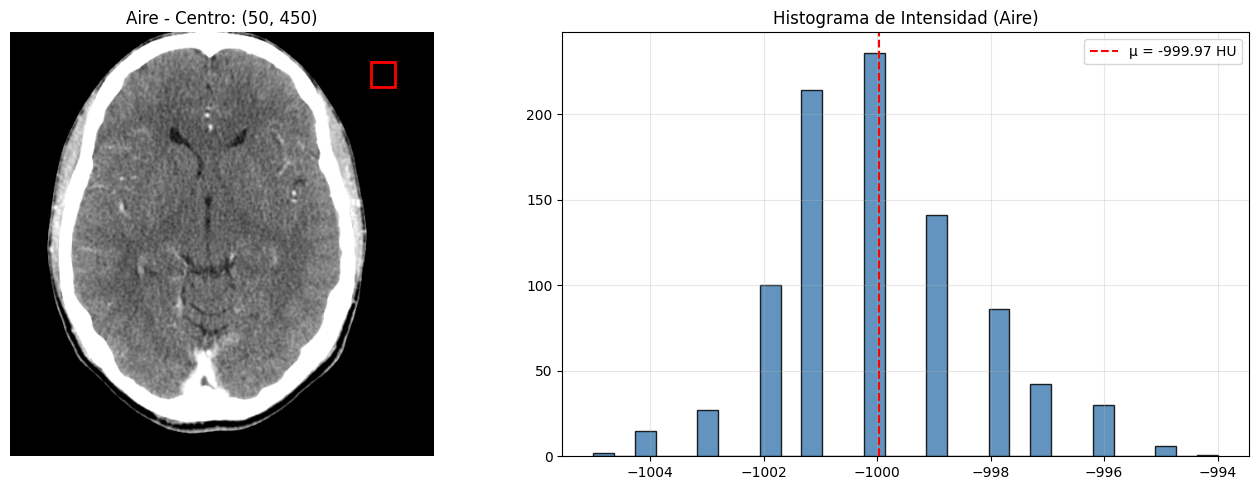

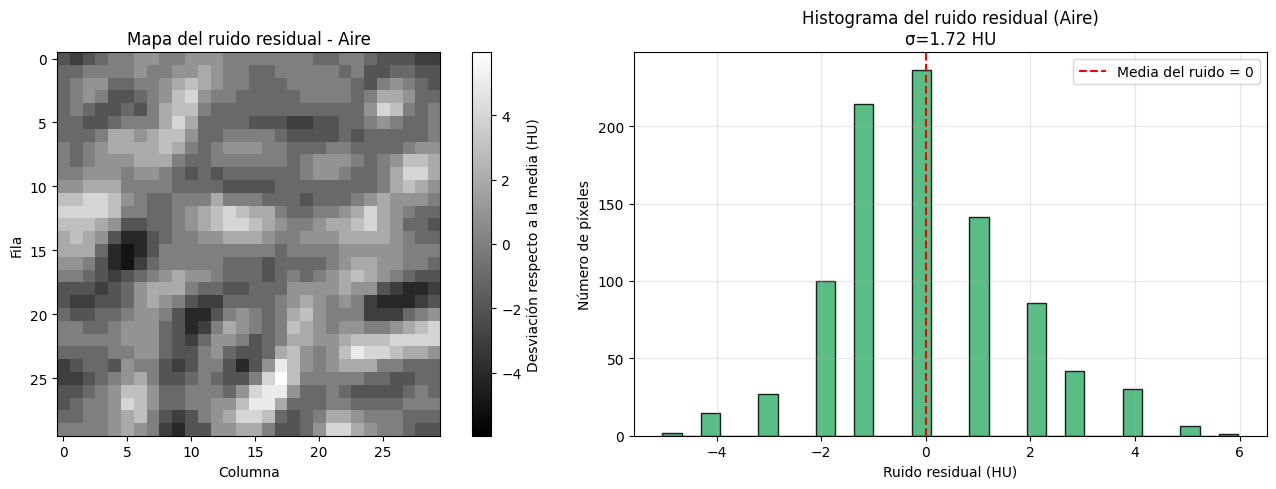

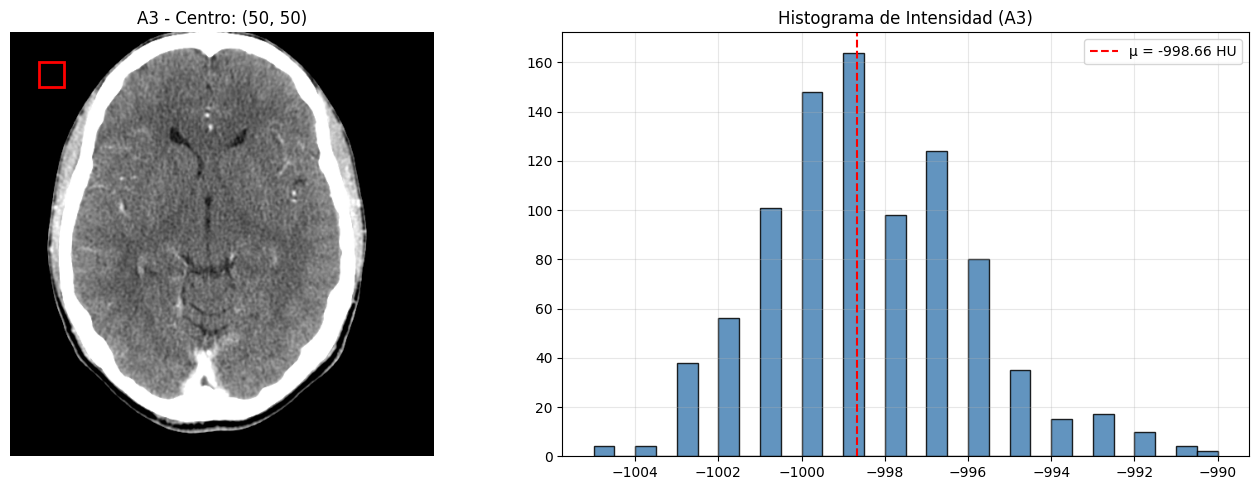

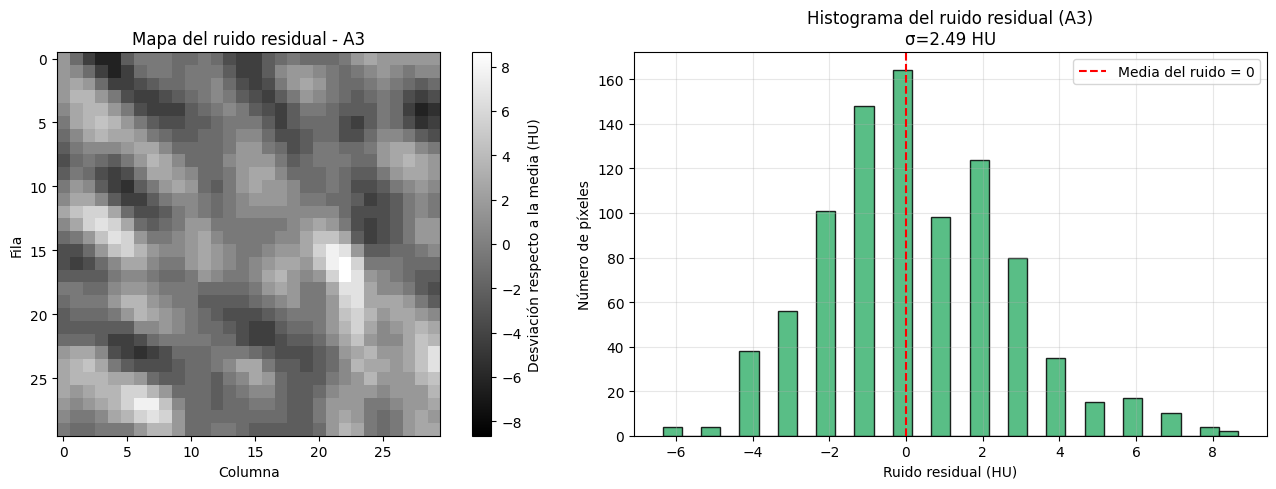

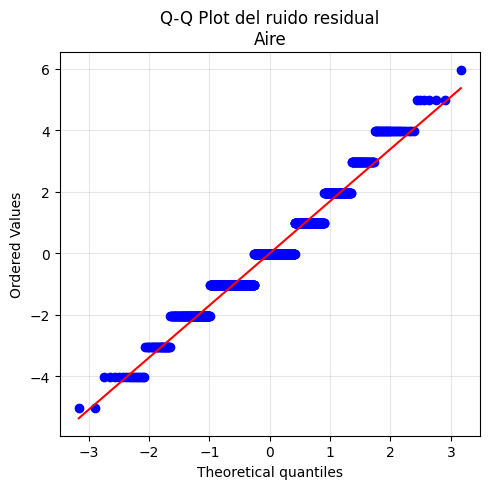

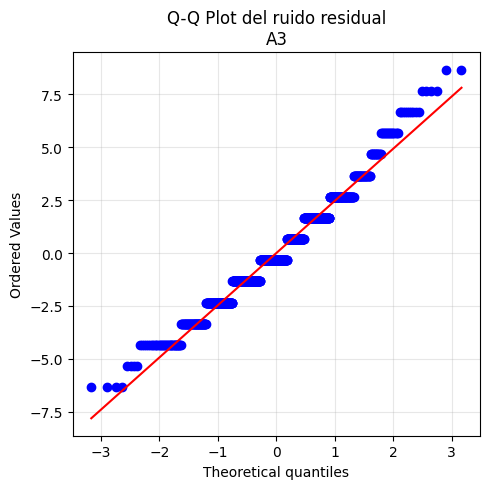


DIAGNÓSTICO SINTETIZADO DEL RUIDO

[Aire]
  • Factor Fano D = 0.123808
  • Veredicto: GAUSSIANO de reconstrucción (post-FBP)
  • Correlación Espacial: H=0.787, V=0.747

[A3]
  • Factor Fano D = 0.244513
  • Veredicto: GAUSSIANO de reconstrucción (post-FBP)
  • Correlación Espacial: H=0.821, V=0.824


In [45]:
# ============================================================
# PIPELINE DE EJECUCIÓN Y DIAGNÓSTICO DE RUIDO EN ROIs
# ============================================================

# Definimos las coordenadas de las ROIs a evaluar
rois = {
    "Aire": (50, 450),
    "A3": (50, 50)
}

# Cargamos los datos de la imagen usando el path unificado
ds, hu_array, pixel_array_crudo = cargar_dicom_hu("imagenes/tomografia craneo/Series 500 [CT - ANGIOGRAFÍA CRANEAL]/1.3.6.1.4.1.5962.99.1.2786334768.1849416866.1385765836848.688.0.dcm")


resultados_ruido = []
datos_rois = {}
datos_ruido = {}

# Procesamiento estadístico de cada ROI
for nombre, centro in rois.items():
    roi_hu = extraer_roi(hu_array, centro, mitad_lado=15)
    roi_cruda = extraer_roi(pixel_array_crudo, centro, mitad_lado=15)

    ruido, resultado = analizar_ruido(roi_hu, roi_cruda, nombre)

    resultados_ruido.append(resultado)
    datos_rois[nombre] = roi_hu
    datos_ruido[nombre] = ruido

# 1. Impresión de Reporte Estadístico en Consola
for resultado in resultados_ruido:
    imprimir_resultados_ruido(resultado)

# 2. Visualización Gráfica (Histograma, ROI y Ruido Residual)
for nombre in rois:
    visualizar_roi_y_ruido(
        hu_array, datos_rois[nombre], datos_ruido[nombre],
        rois[nombre], nombre=nombre, mitad_lado=15
    )

# 3. Gráficas de Probabilidad Normal (Q-Q Plots)
for nombre in rois:
    mostrar_qqplot_ruido(datos_ruido[nombre], nombre)

# 4. Diagnóstico Final Integrado
diagnostico_final_ruido(resultados_ruido)

## Filtrado Espacial: Convolución

A continuación, se define un motor de convolución a bajo nivel utilizando únicamente ciclos `for` y listas de Python. Esto permite comprender cómo se aplican los filtros (kernels) sobre las imágenes DICOM (o sus ROIs extraídas) controlando explícitamente el tratamiento de los bordes.

In [46]:
def _indice_borde(i, n, modo):
    """Índice válido (0..n-1) cuando i se sale de la imagen."""
    if 0 <= i < n:
        return i
    if modo == "replicar":              # repite el píxel del borde
        return 0 if i < 0 else n - 1
    if modo == "reflejar":              # espejo:  ... c b a | a b c ...
        while i < 0 or i >= n:
            if i < 0:
                i = -i - 1
            if i >= n:
                i = 2 * n - 1 - i
        return i
    raise ValueError("modo debe ser 'replicar', 'reflejar' o 'ceros'")

def _rellenar_bordes(img, p, modo):
    """Agrega p filas/columnas alrededor (img es lista de listas). Hecho con for."""
    H, W = len(img), len(img[0])
    nueva = []
    for i in range(-p, H + p):
        fila = []
        for j in range(-p, W + p):
            if modo == "ceros":
                fila.append(img[i][j] if (0 <= i < H and 0 <= j < W) else 0.0)
            else:
                fila.append(img[_indice_borde(i, H, modo)][_indice_borde(j, W, modo)])
        nueva.append(fila)
    return nueva

def tamano_resultante(alto, ancho, k, recuperar_bordes=False):
    if recuperar_bordes:
        return alto, ancho
    p = k // 2
    return alto - 2 * p, ancho - 2 * p

def convolucion(imagen, kernel, recuperar_bordes=False, modo_borde="replicar", voltear_kernel=False):
    """
    Convolución.
    imagen           : matriz 2D.   kernel: matriz cuadrada de tamaño impar.
    recuperar_bordes : False -> salida más pequeña | True -> padding y salida del mismo tamaño.
    modo_borde       : 'replicar', 'reflejar' o 'ceros' (solo si recuperar_bordes=True).
    Devuelve una imagen NUEVA (float64). No modifica la original.
    """
    imagen = np.asarray(imagen); kernel = np.asarray(kernel, dtype=float)
    if imagen.ndim != 2:
        raise ValueError("La imagen debe ser 2D")
    if kernel.ndim != 2 or kernel.shape[0] != kernel.shape[1]:
        raise ValueError("El kernel debe ser cuadrado")
    k = kernel.shape[0]
    if k % 2 == 0:
        raise ValueError("El kernel debe tener un tamaño impar")
    p = k // 2
    if voltear_kernel:
        kernel = kernel[::-1, ::-1]

    img = imagen.astype(float).tolist()            # copia independiente
    ker = kernel.tolist()
    if recuperar_bordes:
        img = _rellenar_bordes(img, p, modo_borde)
    H, W = len(img), len(img[0])
    alto_out, ancho_out = H - 2 * p, W - 2 * p
    if alto_out <= 0 or ancho_out <= 0:
        raise ValueError("El kernel es demasiado grande para esta imagen")

    salida = [[0.0] * ancho_out for _ in range(alto_out)]
    for i in range(alto_out):
        for j in range(ancho_out):
            suma = 0.0
            for u in range(k):
                for v in range(k):
                    suma += ker[u][v] * img[i + u][j + v]
            salida[i][j] = suma
    return np.array(salida)

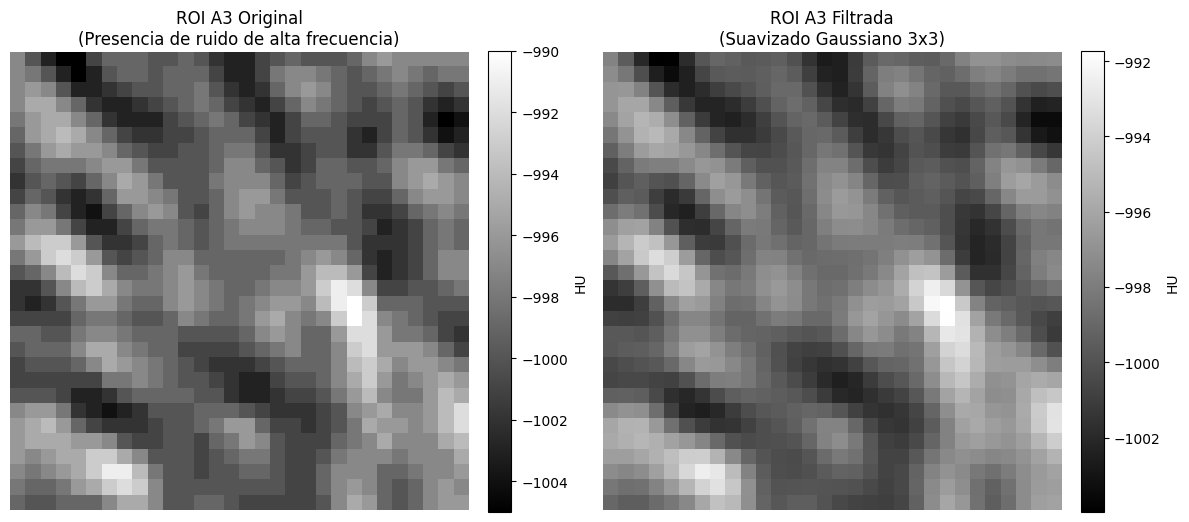

In [47]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Definir el kernel de 3x3 de acuerdo con los pesos proporcionados
kernel_gaussianoSNM = np.array([
    [0.058550, 0.096532, 0.058550],
    [0.096532, 0.159155, 0.096532],
    [0.058550, 0.096532, 0.058550]
])
kernel_gaussiano = np.array([
    [0.075115, 0.123843, 0.075115],
    [0.123843, 0.204167, 0.123843],
    [0.075115, 0.123843, 0.075115]
])

# Normalizar el kernel para asegurar que la ganancia sea unitaria y mantener la escala de grises original
kernel_gaussiano = kernel_gaussiano / np.sum(kernel_gaussiano)

# 2. Extraer la ROI de A3 que tenemos en memoria (con .copy() para evitar mutaciones)
roi_a3 = datos_rois["A3"].copy()

# 3. Aplicar la convolución recuperando bordes mediante replicación
roi_filtrada = convolucion(
    imagen=roi_a3,
    kernel=kernel_gaussiano,
    recuperar_bordes=True,
    modo_borde="replicar"
)

# 4. Visualización comparativa de los resultados
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

# ROI original
im0 = axes[0].imshow(roi_a3, cmap="gray")
axes[0].set_title("ROI A3 Original\n(Presencia de ruido de alta frecuencia)")
axes[0].axis("off")
plt.colorbar(im0, ax=axes[0], fraction=0.046, pad=0.04, label="HU")

# ROI filtrada
im1 = axes[1].imshow(roi_filtrada, cmap="gray")
axes[1].set_title("ROI A3 Filtrada\n(Suavizado Gaussiano 3x3)")
axes[1].axis("off")
plt.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04, label="HU")

plt.tight_layout()
plt.show()

## 1.7 Reutilizando el suavizado (convolución del proyecto)

La función `convolucion()` **ya existe** en el proyecto (hecha por el equipo) y es **genérica**: se puede aplicar a cualquier matriz. La reutilizamos sobre la imagen plana (canal por canal) para mostrar que **el mismo motor sirve para las 3 imágenes**. No se modifica la función original.


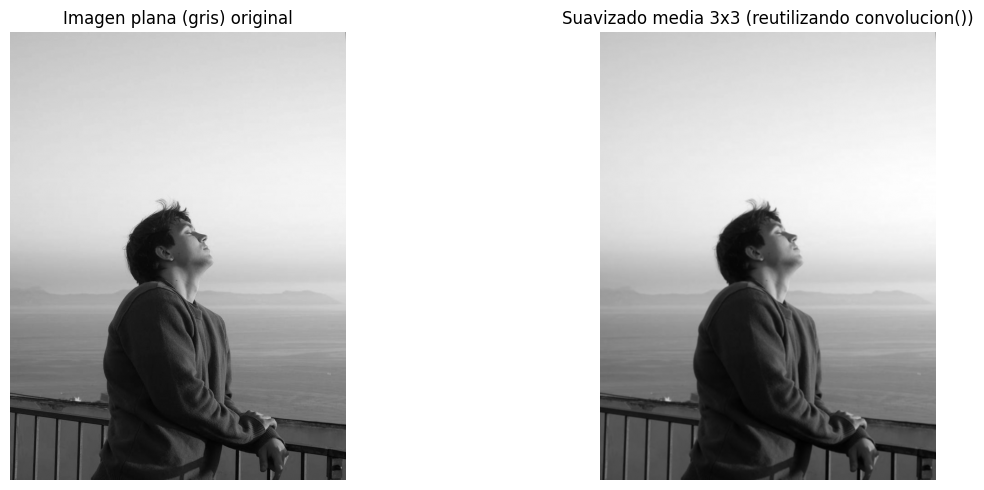

In [48]:
# Convolución gaussiana reutilizando la función del proyecto.
# NOTA: la celda de convolución está más abajo en el notebook; se ejecuta después.
# Esta celda está preparada para ejecutarse CUANDO 'convolucion' ya esté definida.
# (Si se ejecuta antes, se omite por el try/except.)

try:
    kernel_media = np.array([[1,1,1],[1,1,1],[1,1,1]], dtype=float) / 9.0
    gris = imagen_plana.mean(axis=2)
    plana_suavizada = convolucion(gris, kernel_media, recuperar_bordes=True, modo_borde="replicar")

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    axes[0].imshow(gris, cmap="gray"); axes[0].set_title("Imagen plana (gris) original"); axes[0].axis("off")
    axes[1].imshow(plana_suavizada, cmap="gray"); axes[1].set_title("Suavizado media 3x3 (reutilizando convolucion())"); axes[1].axis("off")
    plt.tight_layout(); plt.show()
except NameError:
    print("La función 'convolucion' aún no está definida en el notebook.")
    print("Ejecuta primero las celdas de convolución del proyecto y vuelve a correr esta celda.")
